In [ ]:

# STEP 1: Load the real-world Diabetes dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes

# Load dataset
diabetes = load_diabetes(as_frame=True, scaled=False)

X = diabetes.data
y = diabetes.target

print("Dataset shape:", X.shape)
print("Response shape:", y.shape)

print("\nPredictor names:")
print(X.columns.tolist())

print("\nFirst five observations:")
display(X.head())

print("\nSummary statistics:")
display(X.describe())

print("\nMissing values:")
print(X.isnull().sum())


Dataset shape: (442, 10)
Response shape: (442,)

Predictor names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First five observations:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0



Summary statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000



Missing values:
age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64


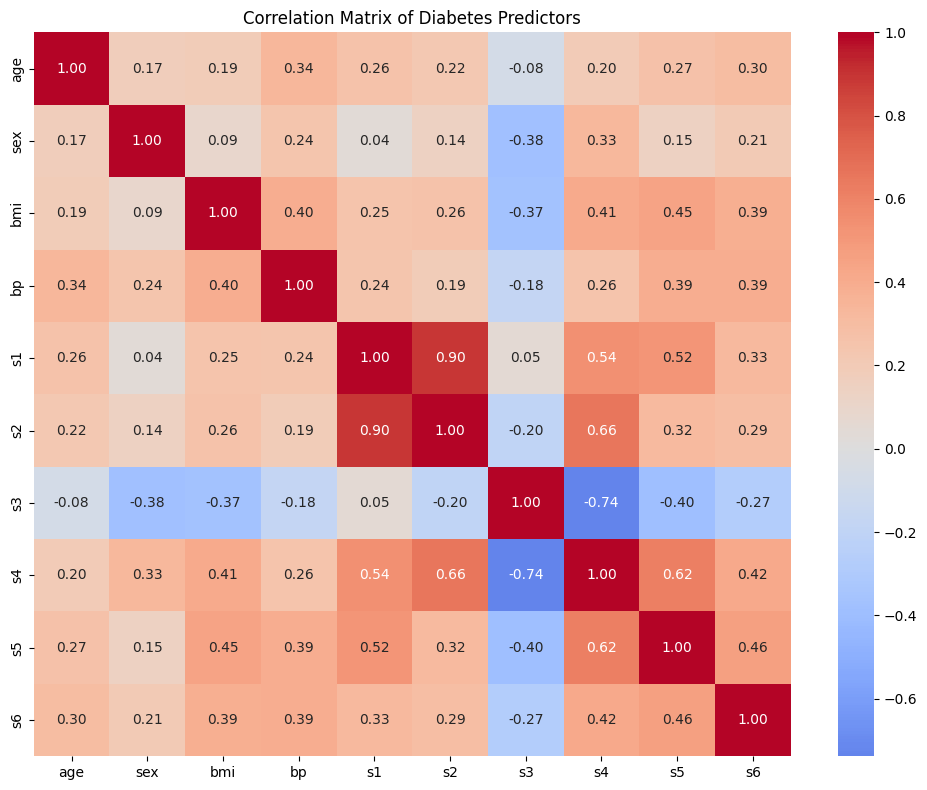

Highly correlated predictor pairs:
('s1', 's2', np.float64(0.8966629578104903))
('s3', 's4', np.float64(-0.7384927292583829))


In [ ]:

# STEP 2: Correlation analysis

correlation_matrix = X.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix of Diabetes Predictors")
plt.tight_layout()
plt.show()

# Identify highly correlated predictor pairs
high_corr = []

for i in range(len(X.columns)):
    for j in range(i + 1, len(X.columns)):
        corr = correlation_matrix.iloc[i, j]

        if abs(corr) >= 0.70:
            high_corr.append(
                (X.columns[i], X.columns[j], corr)
            )

print("Highly correlated predictor pairs:")
for pair in high_corr:
    print(pair)


In [ ]:

# STEP 3: Ordinary LASSO baseline

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Fit LASSO with cross-validation
lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, max_iter=50000)
)

lasso_model.fit(X_train, y_train)

# Predictions
y_pred = lasso_model.predict(X_test)

# Extract coefficients
lasso = lasso_model.named_steps["lassocv"]

coef_table = pd.DataFrame({
    "Predictor": X.columns,
    "Coefficient": lasso.coef_
})

coef_table["Selected"] = (
    np.abs(coef_table["Coefficient"]) > 1e-8
)

print("Optimal alpha:", lasso.alpha_)
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R2:", r2_score(y_test, y_pred))

display(coef_table.sort_values(
    "Coefficient", key=abs, ascending=False
))


Optimal alpha: 1.6552151706972245
Test RMSE: 52.91963089793469
Test R2: 0.4714218340088624


,Predictor,Coefficient,Selected
2,bmi,26.185688,True
8,s5,21.962318,True
3,bp,15.041788,True
6,s3,-11.071885,True
1,sex,-7.980570,True
4,s1,-4.805483,True
9,s6,1.738785,True
0,age,0.000000,False
5,s2,-0.000000,False
7,s4,0.000000,False


In [ ]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.covariance import MinCovDet
from scipy.stats import rankdata

# Standardise training predictors
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Fit baseline LASSO using the previously selected alpha
alpha = lasso.alpha_

base_model = Lasso(
    alpha=alpha,
    max_iter=50000
)

base_model.fit(X_train_scaled, y_train)

base_coef = base_model.coef_
base_support = np.abs(base_coef) > 1e-8

base_residuals = (
    np.asarray(y_train) - base_model.predict(X_train_scaled)
)

print("Number of selected predictors:", base_support.sum())
print("Baseline alpha:", alpha)


Number of selected predictors: 7
Baseline alpha: 1.6552151706972245


In [ ]:

n = len(X_train_scaled)

model_change = np.zeros(n)
coefficient_change = np.zeros(n)

for i in range(n):

    keep = np.arange(n) != i

    model_i = Lasso(
        alpha=alpha,
        max_iter=50000
    )

    model_i.fit(
        X_train_scaled[keep],
        np.asarray(y_train)[keep]
    )

    coef_i = model_i.coef_
    support_i = np.abs(coef_i) > 1e-8

    # Number of changed variable-selection decisions
    model_change[i] = np.sum(
        base_support != support_i
    )

    # Overall coefficient change
    coefficient_change[i] = np.sum(
        np.abs(base_coef - coef_i)
    )

print("Maximum model-selection change:",
      model_change.max())

print("Maximum coefficient change:",
      coefficient_change.max())


Maximum model-selection change: 1.0
Maximum coefficient change: 5.20757175759128


In [ ]:

# Robust residual scores using MAD
residual_median = np.median(base_residuals)

residual_mad = np.median(
    np.abs(base_residuals - residual_median)
)

residual_scale = max(1.4826 * residual_mad, 1e-8)

residual_score = (
    np.abs(base_residuals - residual_median)
    / residual_scale
)

# Robust predictor-space leverage using MCD
mcd = MinCovDet(
    support_fraction=0.75,
    random_state=42
)

mcd.fit(X_train_scaled)

leverage_score = np.sqrt(
    np.maximum(mcd.mahalanobis(X_train_scaled), 0)
)

print("Maximum robust residual score:",
      residual_score.max())

print("Maximum robust leverage score:",
      leverage_score.max())


Maximum robust residual score: 2.7195527672342417
Maximum robust leverage score: 34.197458009721785


In [ ]:

# Convert diagnostic measures into percentile ranks
def percentile_rank(values):
    return (rankdata(values) - 1) / (len(values) - 1)

model_rank = percentile_rank(model_change)
coef_rank = percentile_rank(coefficient_change)
residual_rank = percentile_rank(residual_score)
leverage_rank = percentile_rank(leverage_score)

# Preliminary combined influence score
combined_score = (
    model_rank +
    coef_rank +
    residual_rank +
    leverage_rank
) / 4

# Convert influence score into observation weights
w_min = 0.10
gamma = 4.0

observation_weights = (
    w_min +
    (1 - w_min) /
    (1 + gamma * combined_score**2)
)

# Diagnostic results
influence_table = pd.DataFrame({
    "Observation": X_train.index,
    "Model_Change": model_change,
    "Coefficient_Change": coefficient_change,
    "Residual_Score": residual_score,
    "Leverage_Score": leverage_score,
    "Combined_Score": combined_score,
    "Weight": observation_weights
})

influence_table = influence_table.sort_values(
    "Combined_Score",
    ascending=False
)

display(influence_table.head(15))


,Observation,Model_Change,Coefficient_Change,Residual_Score,Leverage_Score,Combined_Score,Weight
261,382,1.0,3.868079,1.951183,18.735319,0.965554,0.290308
55,141,1.0,3.384544,1.908072,6.934128,0.939986,0.298487
125,123,1.0,3.237093,1.455118,7.270178,0.917259,0.306164
64,152,1.0,3.119730,1.839190,4.794878,0.907315,0.309649
223,256,1.0,2.614654,1.555001,5.323388,0.895241,0.313989
214,336,1.0,1.648150,1.231866,11.699961,0.885298,0.317654
352,102,1.0,3.019617,2.719553,3.505417,0.866832,0.324686
241,230,1.0,1.956609,0.858656,6.682602,0.831321,0.339083
20,380,1.0,3.209881,2.112783,3.122706,0.822798,0.342719
41,7,1.0,2.148423,1.137236,3.894536,0.821378,0.343332


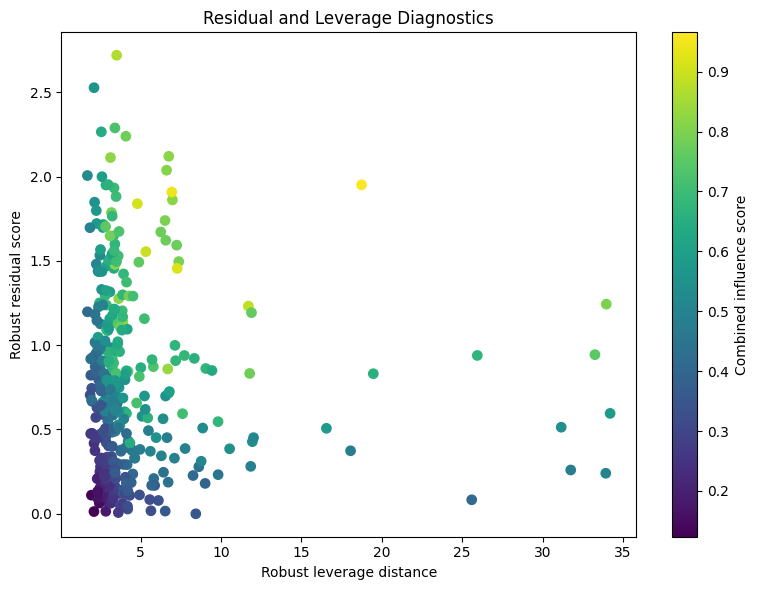

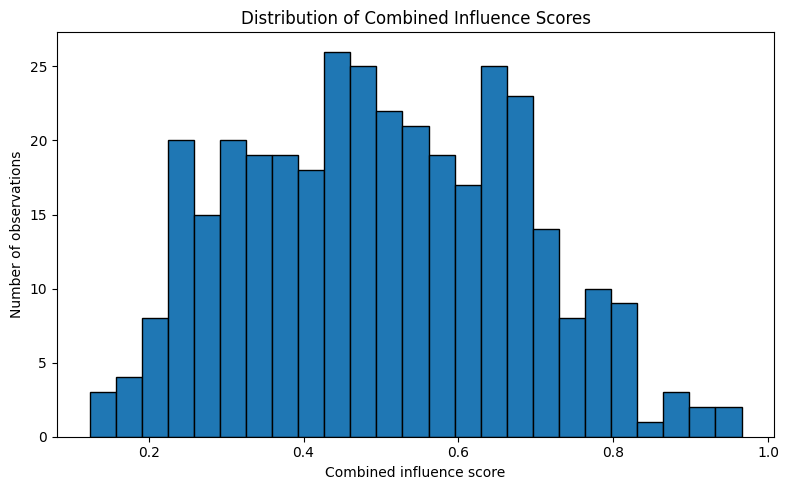

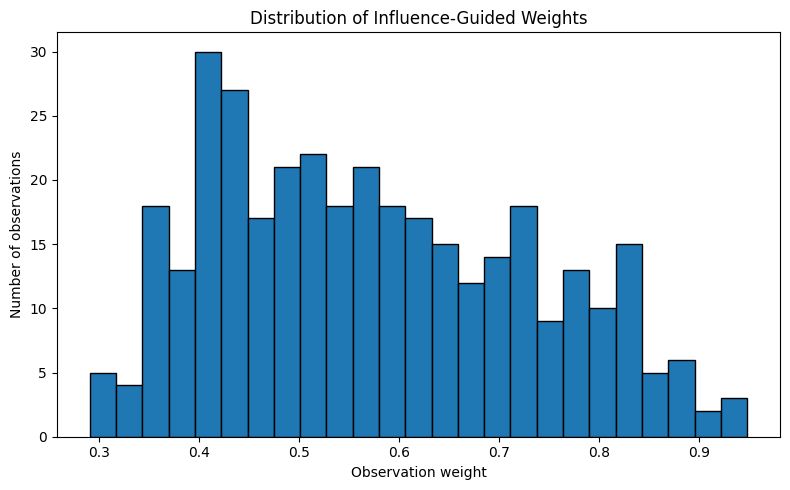

Weight summary:


,Weight
count,353.000000
mean,0.574234
std,0.155835
min,0.290308
25%,0.440233
50%,0.555790
75%,0.694231
max,0.948186


Number of observations with weight below 0.5: 134


In [ ]:

# STEP 5: Visual examination of influential observations

import matplotlib.pyplot as plt
import numpy as np

# Restore original training-row order
diag = influence_table.sort_values(
    "Observation"
).copy()

# Plot 1: Residual score vs leverage score
plt.figure(figsize=(8, 6))

plt.scatter(
    diag["Leverage_Score"],
    diag["Residual_Score"],
    c=diag["Combined_Score"],
    cmap="viridis",
    s=45
)

plt.xlabel("Robust leverage distance")
plt.ylabel("Robust residual score")
plt.title("Residual and Leverage Diagnostics")
plt.colorbar(label="Combined influence score")
plt.tight_layout()
plt.show()

# Plot 2: Combined score distribution
plt.figure(figsize=(8, 5))

plt.hist(
    diag["Combined_Score"],
    bins=25,
    edgecolor="black"
)

plt.xlabel("Combined influence score")
plt.ylabel("Number of observations")
plt.title("Distribution of Combined Influence Scores")
plt.tight_layout()
plt.show()

# Plot 3: Observation weights
plt.figure(figsize=(8, 5))

plt.hist(
    diag["Weight"],
    bins=25,
    edgecolor="black"
)

plt.xlabel("Observation weight")
plt.ylabel("Number of observations")
plt.title("Distribution of Influence-Guided Weights")
plt.tight_layout()
plt.show()

print("Weight summary:")
display(diag["Weight"].describe())

print("Number of observations with weight below 0.5:",
      (diag["Weight"] < 0.5).sum())


In [ ]:

# STEP 6: Identify predictor selection changes

selection_changes = []

for i in range(len(X_train_scaled)):

    keep = np.arange(len(X_train_scaled)) != i

    model_i = Lasso(
        alpha=alpha,
        max_iter=50000
    )

    model_i.fit(
        X_train_scaled[keep],
        np.asarray(y_train)[keep]
    )

    support_i = np.abs(model_i.coef_) > 1e-8

    changed = np.where(base_support != support_i)[0]

    for j in changed:
        selection_changes.append({
            "Observation": X_train.index[i],
            "Changed_Predictor": X.columns[j],
            "Original_Coefficient": base_coef[j],
            "Deleted_Coefficient": model_i.coef_[j]
        })

selection_change_table = pd.DataFrame(selection_changes)

display(selection_change_table)


,Observation,Changed_Predictor,Original_Coefficient,Deleted_Coefficient
0,17,age,0.0,0.029699
1,45,age,0.0,0.008078
2,380,age,0.0,0.123158
3,3,age,0.0,0.145373
4,26,age,0.0,0.166866
5,7,age,0.0,0.047225
6,141,age,0.0,0.129223
7,152,age,0.0,0.372835
8,222,age,0.0,0.112618
9,246,age,0.0,0.020361


In [ ]:

# STEP 7: Compare alternative weighting schemes

D = influence_table.sort_values(
    "Observation"
)["Combined_Score"].to_numpy()

# Method 1: Original weighting
w1 = 0.10 + 0.90 / (1 + 4 * D**2)

# Method 2: More conservative weighting
w2 = 0.50 + 0.50 / (1 + 4 * D**2)

# Method 3: Threshold-based weighting
# Only observations in the highest 10% influence scores
# receive reduced weights.
cutoff = np.quantile(D, 0.90)

w3 = np.where(D >= cutoff, 0.50, 1.00)

comparison = pd.DataFrame({
    "Method": [
        "Original",
        "Conservative",
        "Top 10% threshold"
    ],
    "Mean_Weight": [
        w1.mean(),
        w2.mean(),
        w3.mean()
    ],
    "Minimum_Weight": [
        w1.min(),
        w2.min(),
        w3.min()
    ],
    "Observations_Below_0.5": [
        np.sum(w1 < 0.5),
        np.sum(w2 < 0.5),
        np.sum(w3 < 0.5)
    ],
    "Observations_Downweighted": [
        np.sum(w1 < 0.999),
        np.sum(w2 < 0.999),
        np.sum(w3 < 0.999)
    ]
})

display(comparison)


,Method,Mean_Weight,Minimum_Weight,Observations_Below_0.5,Observations_Downweighted
0,Original,0.574234,0.290308,134,353
1,Conservative,0.763463,0.605727,0,353
2,Top 10% threshold,0.949008,0.500000,0,36


In [ ]:
import pandas as pd
import numpy as np

changes = selection_change_table.copy()

print("Total selection changes:", len(changes))

print("\nChanged predictors:")
print(changes["Changed_Predictor"].value_counts())

print("\nCoefficient magnitude summary:")
print(
    changes.groupby("Changed_Predictor")["Deleted_Coefficient"]
    .agg(["count", "min", "median", "mean", "max"])
)

print("\nNumber of coefficients exceeding different thresholds:")

for threshold in [1e-6, 1e-4, 0.01, 0.05, 0.10]:
    count = (changes["Deleted_Coefficient"].abs() > threshold).sum()
    print(f"Threshold {threshold}: {count}")

Total selection changes: 54

Changed predictors:
Changed_Predictor
age    53
s4      1
Name: count, dtype: int64

Coefficient magnitude summary:
                   count       min    median      mean       max
Changed_Predictor                                               
age                   53  0.000050  0.061594  0.108847  0.961646
s4                     1  0.680447  0.680447  0.680447  0.680447

Number of coefficients exceeding different thresholds:
Threshold 1e-06: 54
Threshold 0.0001: 53
Threshold 0.01: 47
Threshold 0.05: 28
Threshold 0.1: 24


In [ ]:
variables_to_check = [
    "influence_table",
    "selection_change_table",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "X_train_scaled",
    "X_test_scaled"
]

for var in variables_to_check:
    print(var, ":", var in globals())

influence_table : True
selection_change_table : True
X_train : True
X_test : True
y_train : True
y_test : True
X_train_scaled : True
X_test_scaled : False


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Fit scaler using training data only
scaler = StandardScaler()
scaler.fit(X_train)

# Transform both datasets
X_train_check = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify that training scaling matches the existing result
print("Training scaling matches:",
      np.allclose(X_train_check, X_train_scaled))

print("X_test_scaled shape:", X_test_scaled.shape)
print("X_train_scaled shape:", X_train_scaled.shape)

Training scaling matches: True
X_test_scaled shape: (89, 10)
X_train_scaled shape: (353, 10)


In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Align weights with training observations
influence_indexed = influence_table.set_index("Observation")
D = influence_indexed.loc[X_train.index, "Combined_Score"].to_numpy()

# Three weighting schemes
w1 = 0.10 + 0.90 / (1 + 4 * D**2)
w2 = 0.50 + 0.50 / (1 + 4 * D**2)

cutoff = np.quantile(D, 0.90)
w3 = np.where(D >= cutoff, 0.50, 1.00)

weight_schemes = {
    "Original weights": w1,
    "Conservative weights": w2,
    "Top 10% weights": w3
}

alpha = 1.6552151706972245

results = []
coefficient_results = []

for method, weights in weight_schemes.items():

    model = Lasso(alpha=alpha, max_iter=50000)

    model.fit(X_train_scaled, y_train, sample_weight=weights)

    predictions = model.predict(X_test_scaled)

    selected = np.abs(model.coef_) > 1e-8

    results.append({
        "Method": method,
        "Selected_Predictors": int(selected.sum()),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Test_R2": r2_score(y_test, predictions)
    })

    for predictor, coefficient in zip(X_train.columns, model.coef_):
        coefficient_results.append({
            "Method": method,
            "Predictor": predictor,
            "Coefficient": coefficient,
            "Selected": abs(coefficient) > 1e-8
        })

results_df = pd.DataFrame(results)
coefficients_df = pd.DataFrame(coefficient_results)

print("WEIGHTED LASSO PERFORMANCE")
display(results_df.round(4))

print("WEIGHTED LASSO COEFFICIENTS")
display(coefficients_df.round(5))


WEIGHTED LASSO PERFORMANCE


,Method,Selected_Predictors,Test_RMSE,Test_R2
0,Original weights,8,53.0923,0.4680
1,Conservative weights,8,52.9706,0.4704
2,Top 10% weights,8,53.0913,0.4680


WEIGHTED LASSO COEFFICIENTS


,Method,Predictor,Coefficient,Selected
0,Original weights,age,0.78462,True
1,Original weights,sex,-7.91865,True
2,Original weights,bmi,26.19460,True
3,Original weights,bp,14.93002,True
4,Original weights,s1,-4.75158,True
5,Original weights,s2,-0.00000,False
6,Original weights,s3,-10.87670,True
7,Original weights,s4,0.00000,False
8,Original weights,s5,22.57038,True
9,Original weights,s6,0.70941,True


In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso

# Reconstruct weights in training-row order
influence_indexed = influence_table.set_index("Observation")
D = influence_indexed.loc[X_train.index, "Combined_Score"].to_numpy()

w1 = 0.10 + 0.90 / (1 + 4 * D**2)
w2 = 0.50 + 0.50 / (1 + 4 * D**2)

cutoff = np.quantile(D, 0.90)
w3 = np.where(D >= cutoff, 0.50, 1.00)

schemes = {
    "Ordinary LASSO": None,
    "Original weights": w1,
    "Conservative weights": w2,
    "Top 10% weights": w3
}

X_array = np.asarray(X_train_scaled)
y_array = np.asarray(y_train)

n = len(y_array)
sample_size = int(0.80 * n)
n_repetitions = 100
alpha = 1.6552151706972245

rng = np.random.default_rng(42)

selection_counts = {
    method: np.zeros(X_array.shape[1])
    for method in schemes
}

for repetition in range(n_repetitions):

    sampled_indices = rng.choice(
        n, size=sample_size, replace=False
    )

    for method, weights in schemes.items():

        model = Lasso(
            alpha=alpha,
            max_iter=50000
        )

        if weights is None:
            model.fit(
                X_array[sampled_indices],
                y_array[sampled_indices]
            )
        else:
            model.fit(
                X_array[sampled_indices],
                y_array[sampled_indices],
                sample_weight=weights[sampled_indices]
            )

        selected = np.abs(model.coef_) > 1e-8
        selection_counts[method] += selected.astype(int)

# Calculate selection frequencies
predictors = X_train.columns

frequency_table = pd.DataFrame({
    method: counts / n_repetitions
    for method, counts in selection_counts.items()
}, index=predictors)

frequency_table.index.name = "Predictor"

print("PREDICTOR SELECTION FREQUENCIES")
display(frequency_table.round(3))

print("\nAVERAGE NUMBER OF SELECTED PREDICTORS")

for method in schemes:
    average = selection_counts[method].sum() / n_repetitions
    print(f"{method}: {average:.2f}")


PREDICTOR SELECTION FREQUENCIES


,Ordinary LASSO,Original weights,Conservative weights,Top 10% weights
Predictor,,,,
age,0.53,0.76,0.58,0.90
sex,1.00,1.00,1.00,1.00
bmi,1.00,1.00,1.00,1.00
bp,1.00,1.00,1.00,1.00
s1,0.94,0.87,0.93,0.90
s2,0.09,0.27,0.14,0.28
s3,1.00,1.00,1.00,1.00
s4,0.39,0.08,0.25,0.17
s5,1.00,1.00,1.00,1.00



AVERAGE NUMBER OF SELECTED PREDICTORS
Ordinary LASSO: 7.82
Original weights: 7.71
Conservative weights: 7.75
Top 10% weights: 7.94


In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso

# Prepare aligned weights
influence_indexed = influence_table.set_index("Observation")
D = influence_indexed.loc[
    X_train.index, "Combined_Score"
].to_numpy()

w1 = 0.10 + 0.90 / (1 + 4 * D**2)
w2 = 0.50 + 0.50 / (1 + 4 * D**2)

cutoff = np.quantile(D, 0.90)
w3 = np.where(D >= cutoff, 0.50, 1.00)

schemes = {
    "Ordinary LASSO": None,
    "Original weights": w1,
    "Conservative weights": w2,
    "Top 10% weights": w3
}

X_array = np.asarray(X_train_scaled)
y_array = np.asarray(y_train)

n = len(y_array)
p = X_array.shape[1]
sample_size = int(0.80 * n)
B = 100
alpha = 1.6552151706972245

rng = np.random.default_rng(42)

selection_matrices = {
    method: np.zeros((B, p), dtype=int)
    for method in schemes
}

for b in range(B):

    indices = rng.choice(n, size=sample_size, replace=False)

    for method, weights in schemes.items():

        model = Lasso(alpha=alpha, max_iter=50000)

        if weights is None:
            model.fit(X_array[indices], y_array[indices])
        else:
            model.fit(
                X_array[indices],
                y_array[indices],
                sample_weight=weights[indices]
            )

        selection_matrices[method][b, :] = (
            np.abs(model.coef_) > 1e-8
        ).astype(int)


# Nogueira stability calculation
def nogueira_stability(matrix):

    B, p = matrix.shape

    frequencies = matrix.mean(axis=0)
    mean_selected = matrix.sum(axis=1).mean()

    if mean_selected == 0 or mean_selected == p:
        return np.nan

    observed_variance = (
        B / (B - 1)
    ) * frequencies * (1 - frequencies)

    numerator = observed_variance.mean()

    denominator = (
        (mean_selected / p) *
        (1 - mean_selected / p)
    )

    return 1 - numerator / denominator


stability_results = []

for method, matrix in selection_matrices.items():

    stability_results.append({
        "Method": method,
        "Nogueira_Stability": nogueira_stability(matrix),
        "Average_Selected": matrix.sum(axis=1).mean()
    })

stability_df = pd.DataFrame(stability_results)

print("OVERALL FEATURE-SELECTION STABILITY")
display(stability_df.round(4))


OVERALL FEATURE-SELECTION STABILITY


,Method,Nogueira_Stability,Average_Selected
0,Ordinary LASSO,0.5625,7.82
1,Original weights,0.5633,7.71
2,Conservative weights,0.5690,7.75
3,Top 10% weights,0.5451,7.94


In [ ]:

required_variables = [
    "X_train",
    "y_train",
    "X_train_scaled",
    "influence_table",
    "selection_change_table"
]

for name in required_variables:
    print(name, ":", name in globals())

print("\nTraining data shape:", X_train.shape)
print("Training target shape:", y_train.shape)


X_train : True
y_train : True
X_train_scaled : True
influence_table : True
selection_change_table : True

Training data shape: (353, 10)
Training target shape: (353,)


In [ ]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.covariance import MinCovDet
from scipy.stats import rankdata

# Experiment settings
B = 100
SUBSAMPLE_FRAC = 0.80
RANDOM_STATE = 42

# Use the previously selected LASSO alpha
ALPHA = 1.6552151706972245

# Number of observations and predictors
n, p = X_train.shape
subsample_size = int(SUBSAMPLE_FRAC * n)

print("Number of observations:", n)
print("Number of predictors:", p)
print("Subsample size:", subsample_size)
print("Number of repetitions:", B)
print("Fixed alpha:", ALPHA)


Number of observations: 353
Number of predictors: 10
Subsample size: 282
Number of repetitions: 100
Fixed alpha: 1.6552151706972245


In [ ]:

def calculate_influence_weights(X_sub, y_sub, alpha):

    n_sub = X_sub.shape[0]

    # Fit standard LASSO on this subsample
    base_model = Lasso(alpha=alpha, max_iter=50000)
    base_model.fit(X_sub, y_sub)

    base_coef = base_model.coef_.copy()
    base_selected = (np.abs(base_coef) > 1e-8)

    # 1. Leave-one-out influence diagnostics
    model_change = np.zeros(n_sub)
    coefficient_change = np.zeros(n_sub)

    for i in range(n_sub):

        keep = np.ones(n_sub, dtype=bool)
        keep[i] = False

        loo_model = Lasso(alpha=alpha, max_iter=50000)
        loo_model.fit(X_sub[keep], y_sub[keep])

        loo_coef = loo_model.coef_

        loo_selected = (np.abs(loo_coef) > 1e-8)

        model_change[i] = np.sum(
            base_selected != loo_selected
        )

        coefficient_change[i] = np.sum(
            np.abs(base_coef - loo_coef)
        )

    # 2. Robust residual scores
    residuals = y_sub - base_model.predict(X_sub)

    residual_median = np.median(residuals)
    residual_mad = np.median(
        np.abs(residuals - residual_median)
    )

    residual_scale = 1.4826 * residual_mad

    if residual_scale < 1e-10:
        residual_score = np.zeros(n_sub)
    else:
        residual_score = (
            np.abs(residuals - residual_median)
            / residual_scale
        )

    # 3. Robust leverage scores
    try:
        mcd = MinCovDet(random_state=42).fit(X_sub)
        leverage_score = np.sqrt(
            np.maximum(mcd.mahalanobis(X_sub), 0)
        )
    except Exception:
        # Fallback: classical standardized distance
        center = np.mean(X_sub, axis=0)
        scale = np.std(X_sub, axis=0, ddof=1)
        scale[scale < 1e-10] = 1.0

        leverage_score = np.sqrt(
            np.sum(((X_sub - center) / scale) ** 2, axis=1)
        )

    # 4. Convert diagnostics into percentile ranks
    scores = np.column_stack([
        model_change,
        coefficient_change,
        residual_score,
        leverage_score
    ])

    percentile_scores = np.column_stack([
        rankdata(scores[:, j]) / n_sub
        for j in range(scores.shape[1])
    ])

    combined_score = np.mean(percentile_scores, axis=1)

    # 5. Three observation-weight schemes
    weights_original = (
        0.10 + 0.90 / (1 + 4 * combined_score**2)
    )

    weights_conservative = (
        0.50 + 0.50 / (1 + 4 * combined_score**2)
    )

    cutoff = np.quantile(combined_score, 0.90)

    weights_top10 = np.where(
        combined_score >= cutoff, 0.50, 1.00
    )

    return (
        weights_original,
        weights_conservative,
        weights_top10,
        combined_score
    )

print("Influence diagnostic function defined successfully.")


Influence diagnostic function defined successfully.


In [ ]:

B = 100
rng = np.random.default_rng(42)

# Store selection indicators for each method
selection_results = {
    "Ordinary LASSO": [],
    "Original weights": [],
    "Conservative weights": [],
    "Top 10% weights": []
}

for b in range(B):

    # 1. Draw an 80% subsample
    indices = rng.choice(
        n,
        size=subsample_size,
        replace=False
    )

    X_sub_raw = X_train.iloc[indices]
    y_sub = y_train.iloc[indices]

    # 2. Standardize using this subsample only
    scaler = StandardScaler()
    X_sub = scaler.fit_transform(X_sub_raw)

    # 3. Fit ordinary LASSO
    ordinary_model = Lasso(
        alpha=ALPHA,
        max_iter=50000
    )
    ordinary_model.fit(X_sub, y_sub)

    ordinary_selected = (
        np.abs(ordinary_model.coef_) > 1e-8
    )

    # 4. Recalculate influence weights within this subsample
    (
        w_original,
        w_conservative,
        w_top10,
        combined_score
    ) = calculate_influence_weights(
        X_sub, y_sub, ALPHA
    )

    # 5. Fit weighted LASSO models
    weights_dict = {
        "Original weights": w_original,
        "Conservative weights": w_conservative,
        "Top 10% weights": w_top10
    }

    selection_results["Ordinary LASSO"].append(
        ordinary_selected.astype(int)
    )

    for method, weights in weights_dict.items():

        model = Lasso(
            alpha=ALPHA,
            max_iter=50000
        )

        model.fit(
            X_sub,
            y_sub,
            sample_weight=weights
        )

        selected = (
            np.abs(model.coef_) > 1e-8
        )

        selection_results[method].append(
            selected.astype(int)
        )

    if (b + 1) % 5 == 0:
        print(f"Completed repetition {b + 1}/{B}")

print("\nPilot subsampling experiment completed.")


Completed repetition 5/100
Completed repetition 10/100
Completed repetition 15/100
Completed repetition 20/100
Completed repetition 25/100
Completed repetition 30/100
Completed repetition 35/100
Completed repetition 40/100
Completed repetition 45/100
Completed repetition 50/100
Completed repetition 55/100
Completed repetition 60/100
Completed repetition 65/100
Completed repetition 70/100
Completed repetition 75/100
Completed repetition 80/100
Completed repetition 85/100
Completed repetition 90/100
Completed repetition 95/100
Completed repetition 100/100

Pilot subsampling experiment completed.


In [ ]:

feature_names = X_train.columns.tolist()

frequency_tables = {}

for method, results in selection_results.items():

    selection_matrix = np.array(results)

    frequencies = selection_matrix.mean(axis=0)

    frequency_tables[method] = frequencies

frequency_df = pd.DataFrame(
    frequency_tables,
    index=feature_names
)

print("Variable selection frequencies:")
display(frequency_df.round(3))

print("\nAverage number of selected predictors:")

for method, results in selection_results.items():

    average_selected = np.mean(
        np.sum(np.array(results), axis=1)
    )

    print(f"{method}: {average_selected:.3f}")


Variable selection frequencies:


,Ordinary LASSO,Original weights,Conservative weights,Top 10% weights
age,0.53,0.35,0.47,0.35
sex,1.00,1.00,1.00,1.00
bmi,1.00,1.00,1.00,1.00
bp,1.00,1.00,1.00,1.00
s1,0.96,0.78,0.90,0.83
s2,0.06,0.30,0.14,0.29
s3,1.00,1.00,1.00,1.00
s4,0.38,0.20,0.30,0.27
s5,1.00,1.00,1.00,1.00
s6,0.87,0.73,0.83,0.65



Average number of selected predictors:
Ordinary LASSO: 7.800
Original weights: 7.360
Conservative weights: 7.640
Top 10% weights: 7.390


In [ ]:

def nogueira_stability(selection_matrix):

    selection_matrix = np.asarray(selection_matrix)

    B, p = selection_matrix.shape

    # Sample variance of selection indicators
    feature_variances = np.var(
        selection_matrix,
        axis=0,
        ddof=1
    )

    mean_selected = np.mean(
        np.sum(selection_matrix, axis=1)
    )

    selection_proportion = mean_selected / p

    denominator = (
        selection_proportion *
        (1 - selection_proportion)
    )

    if B < 2 or denominator == 0:
        return np.nan

    stability = 1 - (
        np.mean(feature_variances) / denominator
    )

    return stability


# Calculate stability for all four methods
stability_results = []

for method, results in selection_results.items():

    selection_matrix = np.array(results)

    stability = nogueira_stability(selection_matrix)

    average_selected = np.mean(
        np.sum(selection_matrix, axis=1)
    )

    stability_results.append({
        "Method": method,
        "Nogueira Stability": stability,
        "Average Selected Predictors": average_selected
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))


,Method,Nogueira Stability,Average Selected Predictors
0,Ordinary LASSO,0.5923,7.80
1,Original weights,0.4977,7.36
2,Conservative weights,0.5459,7.64
3,Top 10% weights,0.4768,7.39


In [ ]:

def nogueira_stability(selection_matrix):

    Z = np.asarray(selection_matrix, dtype=float)

    B, p = Z.shape

    # Sample variance of each predictor's selection indicator
    feature_variances = np.var(Z, axis=0, ddof=1)

    # Average number of selected predictors
    mean_selected = np.mean(np.sum(Z, axis=1))

    selection_fraction = mean_selected / p

    denominator = (
        selection_fraction * (1 - selection_fraction)
    )

    if denominator == 0:
        return np.nan

    stability = (
        1 - np.mean(feature_variances) / denominator
    )

    return stability


print("Verified Nogueira stability scores:\n")

for method, results in selection_results.items():

    matrix = np.asarray(results)

    score = nogueira_stability(matrix)

    print(f"{method}: {score:.4f}")


Verified Nogueira stability scores:

Ordinary LASSO: 0.5799
Original weights: 0.4611
Conservative weights: 0.5705
Top 10% weights: 0.4224


In [ ]:

print("Checking stored selection matrices:\n")

for method, results in selection_results.items():

    matrix = np.asarray(results)

    print(
        method,
        "| Shape:", matrix.shape,
        "| Nogueira:", round(
            nogueira_stability(matrix), 4
        )
    )


Checking stored selection matrices:

Ordinary LASSO | Shape: (100, 10) | Nogueira: 0.5923
Original weights | Shape: (100, 10) | Nogueira: 0.4977
Conservative weights | Shape: (100, 10) | Nogueira: 0.5459
Top 10% weights | Shape: (100, 10) | Nogueira: 0.4768


In [ ]:

import numpy as np
import pandas as pd

# Synthetic experiment settings
N = 200
P = 20

TRUE_BETA = np.zeros(P)
TRUE_BETA[:5] = [3.0, 1.5, 2.0, -2.0, -1.5]

CORRELATIONS = [0.0, 0.5, 0.9]
CONTAMINATION_LEVELS = [0.0, 0.05, 0.10]

CONTAMINATION_TYPES = [
    "none",
    "response",
    "leverage",
    "cellwise"
]

N_REPETITIONS = 100

print("Synthetic experiment settings")
print("-----------------------------")
print("Sample size:", N)
print("Predictors:", P)
print("True nonzero coefficients:", np.sum(TRUE_BETA != 0))
print("Correlations:", CORRELATIONS)
print("Contamination levels:", CONTAMINATION_LEVELS)
print("Contamination types:", CONTAMINATION_TYPES)
print("Repetitions:", N_REPETITIONS)


Synthetic experiment settings
-----------------------------
Sample size: 200
Predictors: 20
True nonzero coefficients: 5
Correlations: [0.0, 0.5, 0.9]
Contamination levels: [0.0, 0.05, 0.1]
Contamination types: ['none', 'response', 'leverage', 'cellwise']
Repetitions: 100


In [ ]:

def generate_synthetic_data(
    n=200,
    p=20,
    rho=0.5,
    contamination=0.0,
    contamination_type="none",
    seed=42
):

    rng = np.random.default_rng(seed)

    # Equicorrelation covariance matrix
    covariance = (
        (1 - rho) * np.eye(p)
        + rho * np.ones((p, p))
    )

    # Generate clean predictors
    X = rng.multivariate_normal(
        mean=np.zeros(p),
        cov=covariance,
        size=n
    )

    beta = np.zeros(p)
    beta[:5] = [3.0, 1.5, 2.0, -2.0, -1.5]

    # Generate clean response
    noise = rng.normal(0, 1, n)
    y = X @ beta + noise

    if contamination > 0:

        if contamination_type == "response":

            count = int(round(contamination * n))
            rows = rng.choice(n, count, replace=False)

            signs = rng.choice([-1, 1], size=count)
            y[rows] += signs * 10.0

        elif contamination_type == "leverage":

            count = int(round(contamination * n))
            rows = rng.choice(n, count, replace=False)

            signs = rng.choice([-1, 1], size=count)

            # Shift entire predictor vectors.
            # The original response is retained.
            X[rows] += 5.0 * signs[:, None]

        elif contamination_type == "cellwise":

            count = int(round(contamination * n * p))

            cells = rng.choice(
                n * p,
                count,
                replace=False
            )

            signs = rng.choice([-1, 1], size=count)

            X.flat[cells] += 5.0 * signs

    return X, y, beta


# Test one example
X_test_sim, y_test_sim, beta_test_sim = (
    generate_synthetic_data(
        n=N,
        p=P,
        rho=0.5,
        contamination=0.05,
        contamination_type="response",
        seed=42
    )
)

print("Generated X shape:", X_test_sim.shape)
print("Generated y shape:", y_test_sim.shape)
print("True coefficients:", beta_test_sim)
print("Number of nonzero coefficients:",
      np.sum(beta_test_sim != 0))


Generated X shape: (200, 20)
Generated y shape: (200,)
True coefficients: [ 3.   1.5  2.  -2.  -1.5  0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.   0. ]
Number of nonzero coefficients: 5


In [ ]:

print("VALIDATION OF CONTAMINATION MECHANISMS")
print("--------------------------------------")

for contamination_type in CONTAMINATION_TYPES:

    X_check, y_check, beta_check = generate_synthetic_data(
        n=200,
        p=20,
        rho=0.5,
        contamination=0.10,
        contamination_type=contamination_type,
        seed=42
    )

    print("\nContamination type:", contamination_type)
    print("X shape:", X_check.shape)
    print("Y shape:", y_check.shape)
    print("X finite:", np.isfinite(X_check).all())
    print("Y finite:", np.isfinite(y_check).all())

    print(
        "Mean absolute predictor value:",
        round(np.mean(np.abs(X_check)), 3)
    )

    print(
        "Response standard deviation:",
        round(np.std(y_check), 3)
    )


VALIDATION OF CONTAMINATION MECHANISMS
--------------------------------------

Contamination type: none
X shape: (200, 20)
Y shape: (200,)
X finite: True
Y finite: True
Mean absolute predictor value: 0.784
Response standard deviation: 4.166

Contamination type: response
X shape: (200, 20)
Y shape: (200,)
X finite: True
Y finite: True
Mean absolute predictor value: 0.784
Response standard deviation: 5.194

Contamination type: leverage
X shape: (200, 20)
Y shape: (200,)
X finite: True
Y finite: True
Mean absolute predictor value: 1.195
Response standard deviation: 4.166

Contamination type: cellwise
X shape: (200, 20)
Y shape: (200,)
X finite: True
Y finite: True
Mean absolute predictor value: 1.209
Response standard deviation: 4.166


In [ ]:

print("COVARIANCE MATRIX VALIDATION")
print("----------------------------")

for rho in CORRELATIONS:

    covariance = (
        (1 - rho) * np.eye(P)
        + rho * np.ones((P, P))
    )

    eigenvalues = np.linalg.eigvalsh(covariance)

    condition_number = (
        eigenvalues.max() / eigenvalues.min()
    )

    print(f"\nCorrelation: {rho}")
    print("Smallest eigenvalue:", round(eigenvalues.min(), 4))
    print("Largest eigenvalue:", round(eigenvalues.max(), 4))
    print("Condition number:", round(condition_number, 4))
    print("Positive definite:", np.all(eigenvalues > 0))


COVARIANCE MATRIX VALIDATION
----------------------------

Correlation: 0.0
Smallest eigenvalue: 1.0
Largest eigenvalue: 1.0
Condition number: 1.0
Positive definite: True

Correlation: 0.5
Smallest eigenvalue: 0.5
Largest eigenvalue: 10.5
Condition number: 21.0
Positive definite: True

Correlation: 0.9
Smallest eigenvalue: 0.1
Largest eigenvalue: 18.1
Condition number: 181.0
Positive definite: True


In [ ]:

# SYNTHETIC EXPERIMENT: BASELINE MODELS
# Ordinary LASSO vs Elastic Net
# Training data may be contaminated; test data remains clean.

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------------------------------
# 1. Generate contaminated training data
# --------------------------------------------------

X_train_sim, y_train_sim, beta_true = generate_synthetic_data(
    n=N,
    p=P,
    rho=0.5,
    contamination=0.05,
    contamination_type="response",
    seed=101
)

# --------------------------------------------------
# 2. Generate independent CLEAN test data
# --------------------------------------------------

X_test_sim, y_test_sim, _ = generate_synthetic_data(
    n=100,
    p=P,
    rho=0.5,
    contamination=0.0,
    contamination_type="none",
    seed=202
)

print("Training data shape:", X_train_sim.shape)
print("Test data shape:", X_test_sim.shape)
print("Number of truly active predictors:", np.sum(beta_true != 0))

# --------------------------------------------------
# 3. Standardize predictors
# --------------------------------------------------

scaler_sim = StandardScaler()

X_train_std = scaler_sim.fit_transform(X_train_sim)
X_test_std = scaler_sim.transform(X_test_sim)

# --------------------------------------------------
# 4. Fit Ordinary LASSO
# --------------------------------------------------

lasso_cv = LassoCV(
    cv=5,
    max_iter=50000,
    random_state=42
)

lasso_cv.fit(X_train_std, y_train_sim)

lasso_pred = lasso_cv.predict(X_test_std)

lasso_beta = lasso_cv.coef_ / scaler_sim.scale_

# --------------------------------------------------
# 5. Fit Elastic Net
# --------------------------------------------------

elastic_cv = ElasticNetCV(
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99],
    cv=5,
    max_iter=50000,
    random_state=42
)

elastic_cv.fit(X_train_std, y_train_sim)

elastic_pred = elastic_cv.predict(X_test_std)

elastic_beta = elastic_cv.coef_ / scaler_sim.scale_

# --------------------------------------------------
# 6. Calculate evaluation measures
# --------------------------------------------------

def evaluate_model(name, beta_est, y_pred):

    selected = np.abs(beta_est) > 1e-6
    true_active = beta_true != 0

    tp = np.sum(selected & true_active)
    fp = np.sum(selected & ~true_active)
    fn = np.sum(~selected & true_active)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    return {
        "Method": name,
        "Selected Variables": int(np.sum(selected)),
        "True Positives": int(tp),
        "False Positives": int(fp),
        "Precision": precision,
        "Recall": recall,
        "Test RMSE": np.sqrt(mean_squared_error(y_test_sim, y_pred)),
        "Test R2": r2_score(y_test_sim, y_pred),
        "Coefficient Error": np.linalg.norm(beta_est - beta_true)
    }

baseline_results = pd.DataFrame([
    evaluate_model("Ordinary LASSO", lasso_beta, lasso_pred),
    evaluate_model("Elastic Net", elastic_beta, elastic_pred)
])

print("\nBASELINE MODEL COMPARISON")
display(baseline_results.round(4))

print("\nOPTIMAL PARAMETERS")
print("LASSO alpha:", lasso_cv.alpha_)
print("Elastic Net alpha:", elastic_cv.alpha_)
print("Elastic Net l1_ratio:", elastic_cv.l1_ratio_)


Training data shape: (200, 20)
Test data shape: (100, 20)
Number of truly active predictors: 5

BASELINE MODEL COMPARISON


,Method,Selected Variables,True Positives,False Positives,Precision,Recall,Test RMSE,Test R2,Coefficient Error
0,Ordinary LASSO,13,5,8,0.3846,1.0,1.1210,0.9221,0.7312
1,Elastic Net,13,5,8,0.3846,1.0,1.1218,0.9220,0.7359



OPTIMAL PARAMETERS
LASSO alpha: 0.09420166560248089
Elastic Net alpha: 0.09515319757826349
Elastic Net l1_ratio: 0.99


In [ ]:

# SYNTHETIC EXPERIMENT: ADAPTIVE LASSO
# Pilot LASSO + Adaptive penalty weights

import numpy as np
import pandas as pd

from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------------------------------
# 1. Pilot LASSO model
# --------------------------------------------------

pilot_model = LassoCV(
    cv=5,
    max_iter=50000,
    random_state=42
)

pilot_model.fit(X_train_std, y_train_sim)

pilot_beta = pilot_model.coef_

# --------------------------------------------------
# 2. Calculate adaptive penalty weights
# --------------------------------------------------

GAMMA = 1.0
EPSILON = 0.01

adaptive_weights = (
    np.abs(pilot_beta) + EPSILON
) ** (-GAMMA)

print("Adaptive penalty weights:")
print(np.round(adaptive_weights, 4))

# --------------------------------------------------
# 3. Transform predictors
# --------------------------------------------------

X_train_adaptive = X_train_std / adaptive_weights
X_test_adaptive = X_test_std / adaptive_weights

# --------------------------------------------------
# 4. Fit Adaptive LASSO
# --------------------------------------------------

adaptive_model = LassoCV(
    cv=5,
    max_iter=50000,
    random_state=42
)

adaptive_model.fit(
    X_train_adaptive,
    y_train_sim
)

# --------------------------------------------------
# 5. Recover original-scale coefficients
# --------------------------------------------------

adaptive_beta_std = (
    adaptive_model.coef_ / adaptive_weights
)

adaptive_beta = (
    adaptive_beta_std / scaler_sim.scale_
)

# --------------------------------------------------
# 6. Predictions
# --------------------------------------------------

adaptive_pred = adaptive_model.predict(
    X_test_adaptive
)

# --------------------------------------------------
# 7. Evaluate Adaptive LASSO
# --------------------------------------------------

adaptive_results = pd.DataFrame([
    evaluate_model(
        "Adaptive LASSO",
        adaptive_beta,
        adaptive_pred
    )
])

print("\nADAPTIVE LASSO RESULTS")
display(adaptive_results.round(4))

print("Pilot LASSO alpha:", pilot_model.alpha_)
print("Adaptive LASSO alpha:", adaptive_model.alpha_)
print("Gamma:", GAMMA)


Adaptive penalty weights:
[  0.3262   0.6958   0.622    0.5668   0.7376   3.0722  10.3481 100.
 100.      35.9052 100.     100.       6.1485  49.9407   8.503  100.
   6.7104  13.4111 100.     100.    ]

ADAPTIVE LASSO RESULTS


,Method,Selected Variables,True Positives,False Positives,Precision,Recall,Test RMSE,Test R2,Coefficient Error
0,Adaptive LASSO,6,5,1,0.8333,1.0,1.0618,0.9301,0.4892


Pilot LASSO alpha: 0.09420166560248089
Adaptive LASSO alpha: 0.03817238932559147
Gamma: 1.0


In [ ]:

# INFLUENCE-WEIGHTED ADAPTIVE LASSO
# Combines observation-level influence weights
# with adaptive coefficient penalty weights.

import numpy as np
import pandas as pd
import warnings

from sklearn.linear_model import Lasso
from sklearn.covariance import MinCovDet
from scipy.stats import rankdata
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------------------------------
# 1. Reference model using the pilot LASSO
# --------------------------------------------------

pilot_alpha = pilot_model.alpha_

reference_model = Lasso(
    alpha=pilot_alpha,
    max_iter=50000
)

reference_model.fit(X_train_std, y_train_sim)

reference_beta = reference_model.coef_

reference_selected = (
    np.abs(reference_beta) > 1e-6
)

# --------------------------------------------------
# 2. Leave-one-out influence diagnostics
# --------------------------------------------------

n_obs = X_train_std.shape[0]

model_change = np.zeros(n_obs)
coefficient_change = np.zeros(n_obs)

for i in range(n_obs):

    keep = np.arange(n_obs) != i

    loo_model = Lasso(
        alpha=pilot_alpha,
        max_iter=50000
    )

    loo_model.fit(
        X_train_std[keep],
        y_train_sim[keep]
    )

    loo_beta = loo_model.coef_

    loo_selected = np.abs(loo_beta) > 1e-6

    model_change[i] = np.sum(
        loo_selected != reference_selected
    )

    coefficient_change[i] = np.sum(
        np.abs(loo_beta - reference_beta)
    )

print("Leave-one-out diagnostics completed.")

# --------------------------------------------------
# 3. Robust residual diagnostic
# --------------------------------------------------

residuals = (
    y_train_sim - reference_model.predict(X_train_std)
)

residual_median = np.median(residuals)

residual_mad = np.median(
    np.abs(residuals - residual_median)
)

residual_scale = max(1.4826 * residual_mad, 1e-8)

residual_score = (
    np.abs(residuals - residual_median)
    / residual_scale
)

# --------------------------------------------------
# 4. Robust leverage diagnostic
# --------------------------------------------------

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    try:
        robust_cov = MinCovDet(
            random_state=42
        ).fit(X_train_std)

        leverage_score = np.sqrt(
            np.maximum(
                robust_cov.mahalanobis(X_train_std),
                0
            )
        )

    except Exception:
        print("Robust covariance failed; using classical covariance.")

        center = np.mean(X_train_std, axis=0)
        covariance = np.cov(X_train_std, rowvar=False)

        inverse_covariance = np.linalg.pinv(covariance)

        differences = X_train_std - center

        leverage_score = np.sqrt(
            np.maximum(
                np.einsum(
                    "ij,jk,ik->i",
                    differences,
                    inverse_covariance,
                    differences
                ),
                0
            )
        )

# --------------------------------------------------
# 5. Combine four influence diagnostics
# --------------------------------------------------

diagnostics = np.column_stack([
    model_change,
    coefficient_change,
    residual_score,
    leverage_score
])

diagnostic_ranks = np.column_stack([
    rankdata(diagnostics[:, j]) / n_obs
    for j in range(diagnostics.shape[1])
])

combined_influence = np.mean(
    diagnostic_ranks,
    axis=1
)

# --------------------------------------------------
# 6. Calculate observation weights
# --------------------------------------------------

observation_weights = (
    0.1 + 0.9 / (1 + 4 * combined_influence**2)
)

# Normalize weights to have mean one
observation_weights = (
    observation_weights / np.mean(observation_weights)
)

print("\nOBSERVATION WEIGHT SUMMARY")
print(pd.Series(observation_weights).describe().round(4))

# --------------------------------------------------
# 7. Adaptive coefficient penalty weights
# --------------------------------------------------

GAMMA = 1.0
EPSILON = 0.01

adaptive_weights_iw = (
    np.abs(pilot_beta) + EPSILON
) ** (-GAMMA)

# Transform predictors
X_train_iw = (
    X_train_std / adaptive_weights_iw
)

X_test_iw = (
    X_test_std / adaptive_weights_iw
)

# --------------------------------------------------
# 8. Fit Influence-Weighted Adaptive LASSO
# --------------------------------------------------

iw_adaptive_model = Lasso(
    alpha=adaptive_model.alpha_,
    max_iter=50000
)

iw_adaptive_model.fit(
    X_train_iw,
    y_train_sim,
    sample_weight=observation_weights
)

# Recover original-scale coefficients
iw_beta_std = (
    iw_adaptive_model.coef_ / adaptive_weights_iw
)

iw_beta = (
    iw_beta_std / scaler_sim.scale_
)

# --------------------------------------------------
# 9. Test predictions
# --------------------------------------------------

iw_predictions = iw_adaptive_model.predict(
    X_test_iw
)

# --------------------------------------------------
# 10. Evaluate the proposed candidate method
# --------------------------------------------------

iw_results = pd.DataFrame([
    evaluate_model(
        "Influence-Weighted Adaptive LASSO",
        iw_beta,
        iw_predictions
    )
])

print("\nINFLUENCE-WEIGHTED ADAPTIVE LASSO RESULTS")

display(iw_results.round(4))

print("\nSELECTED PREDICTORS")

selected_predictors = np.where(
    np.abs(iw_beta) > 1e-6
)[0]

print(selected_predictors)

print("\nNUMBER OF SELECTED PREDICTORS:",
      len(selected_predictors))


Leave-one-out diagnostics completed.

OBSERVATION WEIGHT SUMMARY
count    200.0000
mean       1.0000
std        0.2745
min        0.5231
25%        0.7855
50%        0.9812
75%        1.2242
max        1.6527
dtype: float64

INFLUENCE-WEIGHTED ADAPTIVE LASSO RESULTS


,Method,Selected Variables,True Positives,False Positives,Precision,Recall,Test RMSE,Test R2,Coefficient Error
0,Influence-Weighted Adaptive LASSO,6,5,1,0.8333,1.0,1.0294,0.9343,0.4231



SELECTED PREDICTORS
[0 1 2 3 4 5]

NUMBER OF SELECTED PREDICTORS: 6


In [ ]:

# REFINE: CROSS-VALIDATION FOR INFLUENCE-WEIGHTED
# ADAPTIVE LASSO

from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Tune alpha using weighted cross-validation

iw_adaptive_cv = LassoCV(
    cv=5,
    max_iter=50000,
    random_state=42
)

iw_adaptive_cv.fit(
    X_train_iw,
    y_train_sim,
    sample_weight=observation_weights
)

# 2. Recover coefficients on the original scale

iw_cv_beta_std = (
    iw_adaptive_cv.coef_ / adaptive_weights_iw
)

iw_cv_beta = (
    iw_cv_beta_std / scaler_sim.scale_
)

# 3. Predict on clean test data

iw_cv_predictions = iw_adaptive_cv.predict(
    X_test_iw
)

# 4. Evaluate the refined model

iw_cv_results = pd.DataFrame([
    evaluate_model(
        "Influence-Weighted Adaptive LASSO (CV)",
        iw_cv_beta,
        iw_cv_predictions
    )
])

print("WEIGHTED CROSS-VALIDATION RESULTS")
display(iw_cv_results.round(4))

print("Selected alpha:", iw_adaptive_cv.alpha_)

print(
    "Selected predictors:",
    np.where(np.abs(iw_cv_beta) > 1e-6)[0]
)


WEIGHTED CROSS-VALIDATION RESULTS


,Method,Selected Variables,True Positives,False Positives,Precision,Recall,Test RMSE,Test R2,Coefficient Error
0,Influence-Weighted Adaptive LASSO (CV),7,5,2,0.7143,1.0,1.0416,0.9327,0.4442


Selected alpha: 0.020545217419187335
Selected predictors: [ 0  1  2  3  4  5 12]


In [ ]:

# EXPERIMENTAL DESIGN: 21 SYNTHETIC CONDITIONS
# 3 correlation levels
# 3 contamination mechanisms
# 2 contamination levels
# 3 clean baseline conditions

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Experimental settings
# --------------------------------------------------

CORRELATIONS = [0.0, 0.5, 0.9]

CONTAMINATION_LEVELS = [0.05, 0.10]

CONTAMINATION_TYPES = [
    "response",
    "leverage",
    "cellwise"
]

PILOT_REPETITIONS = 5
FINAL_REPETITIONS = 100

# --------------------------------------------------
# 2. Construct experimental conditions
# --------------------------------------------------

conditions = []

# Clean conditions: one for each correlation level
for rho in CORRELATIONS:

    conditions.append({
        "rho": rho,
        "contamination": 0.0,
        "contamination_type": "none"
    })

# Contaminated conditions
for rho in CORRELATIONS:

    for contamination_type in CONTAMINATION_TYPES:

        for contamination in CONTAMINATION_LEVELS:

            conditions.append({
                "rho": rho,
                "contamination": contamination,
                "contamination_type": contamination_type
            })

# --------------------------------------------------
# 3. Convert to DataFrame
# --------------------------------------------------

condition_table = pd.DataFrame(conditions)

condition_table.insert(
    0,
    "Condition",
    range(1, len(condition_table) + 1)
)

print("SYNTHETIC EXPERIMENTAL DESIGN")
print("--------------------------------")

display(condition_table)

# --------------------------------------------------
# 4. Validate the experimental design
# --------------------------------------------------

print("\nDESIGN VALIDATION")
print("-----------------")

print("Total conditions:", len(condition_table))
print("Correlation levels:", len(CORRELATIONS))
print("Contamination mechanisms:", len(CONTAMINATION_TYPES))
print("Contamination levels:", len(CONTAMINATION_LEVELS))
print("Pilot repetitions:", PILOT_REPETITIONS)
print("Final repetitions:", FINAL_REPETITIONS)

total_pilot_datasets = (
    len(condition_table) * PILOT_REPETITIONS
)

print("Total pilot datasets:", total_pilot_datasets)

assert len(condition_table) == 21
assert total_pilot_datasets == 105

print("\nExperimental design validated successfully.")


SYNTHETIC EXPERIMENTAL DESIGN
--------------------------------


,Condition,rho,contamination,contamination_type
0,1,0.0,0.00,none
1,2,0.5,0.00,none
2,3,0.9,0.00,none
3,4,0.0,0.05,response
4,5,0.0,0.10,response
5,6,0.0,0.05,leverage
6,7,0.0,0.10,leverage
7,8,0.0,0.05,cellwise
8,9,0.0,0.10,cellwise
9,10,0.5,0.05,response



DESIGN VALIDATION
-----------------
Total conditions: 21
Correlation levels: 3
Contamination mechanisms: 3
Contamination levels: 2
Pilot repetitions: 5
Final repetitions: 100
Total pilot datasets: 105

Experimental design validated successfully.


In [ ]:

# SIMULATION FRAMEWORK: FOUR-METHOD COMPARISON
# First test on one synthetic dataset.

import numpy as np
import pandas as pd
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, ElasticNetCV, Lasso
from sklearn.covariance import MinCovDet
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from scipy.stats import rankdata

# --------------------------------------------------
# 1. Common evaluation function
# --------------------------------------------------

def evaluate_simulation_method(
    method_name, beta_est, predictions, y_test, beta_true
):

    selected = np.abs(beta_est) > 1e-6
    true_active = beta_true != 0

    tp = np.sum(selected & true_active)
    fp = np.sum(selected & ~true_active)
    fn = np.sum(~selected & true_active)

    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0

    return {
        "Method": method_name,
        "Selected": int(np.sum(selected)),
        "TP": int(tp),
        "FP": int(fp),
        "Precision": precision,
        "Recall": recall,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
        "Coefficient_Error": np.linalg.norm(beta_est - beta_true)
    }


# --------------------------------------------------
# 2. Influence diagnostic function
# --------------------------------------------------

def calculate_simulation_influence_weights(
    X, y, alpha
):

    n_obs = X.shape[0]

    reference_model = Lasso(
        alpha=alpha,
        max_iter=50000
    )

    reference_model.fit(X, y)

    reference_beta = reference_model.coef_
    reference_selected = np.abs(reference_beta) > 1e-6

    model_change = np.zeros(n_obs)
    coefficient_change = np.zeros(n_obs)

    for i in range(n_obs):

        keep = np.arange(n_obs) != i

        loo_model = Lasso(
            alpha=alpha,
            max_iter=50000
        )

        loo_model.fit(X[keep], y[keep])

        loo_beta = loo_model.coef_

        model_change[i] = np.sum(
            (np.abs(loo_beta) > 1e-6) != reference_selected
        )

        coefficient_change[i] = np.sum(
            np.abs(loo_beta - reference_beta)
        )

    # Robust residual scores
    residuals = y - reference_model.predict(X)

    residual_median = np.median(residuals)
    residual_mad = np.median(
        np.abs(residuals - residual_median)
    )

    residual_scale = max(
        1.4826 * residual_mad, 1e-8
    )

    residual_score = (
        np.abs(residuals - residual_median)
        / residual_scale
    )

    # Robust leverage scores
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        try:
            robust_cov = MinCovDet(
                random_state=42
            ).fit(X)

            leverage_score = np.sqrt(
                np.maximum(
                    robust_cov.mahalanobis(X), 0
                )
            )

        except Exception:
            center = np.mean(X, axis=0)
            covariance = np.cov(X, rowvar=False)
            inverse_covariance = np.linalg.pinv(covariance)

            differences = X - center

            leverage_score = np.sqrt(
                np.maximum(
                    np.einsum(
                        "ij,jk,ik->i",
                        differences,
                        inverse_covariance,
                        differences
                    ),
                    0
                )
            )

    diagnostics = np.column_stack([
        model_change,
        coefficient_change,
        residual_score,
        leverage_score
    ])

    ranks = np.column_stack([
        rankdata(diagnostics[:, j]) / n_obs
        for j in range(diagnostics.shape[1])
    ])

    combined_score = np.mean(ranks, axis=1)

    weights = (
        0.1 + 0.9 / (1 + 4 * combined_score**2)
    )

    weights = weights / np.mean(weights)

    return weights


# --------------------------------------------------
# 3. Fit and evaluate all four methods
# --------------------------------------------------

def run_one_simulation(
    rho=0.5,
    contamination=0.05,
    contamination_type="response",
    seed=101
):

    # Generate contaminated training data
    X_train, y_train, beta_true = generate_synthetic_data(
        n=N,
        p=P,
        rho=rho,
        contamination=contamination,
        contamination_type=contamination_type,
        seed=seed
    )

    # Generate independent clean test data
    X_test, y_test, _ = generate_synthetic_data(
        n=100,
        p=P,
        rho=rho,
        contamination=0.0,
        contamination_type="none",
        seed=seed + 100000
    )

    # Standardize using training data only
    scaler = StandardScaler()

    X_train_std = scaler.fit_transform(X_train)
    X_test_std = scaler.transform(X_test)

    results = []

    # ----------------------------------------------
    # A. Ordinary LASSO
    # ----------------------------------------------

    lasso = LassoCV(
        cv=5,
        max_iter=50000,
        random_state=42
    )

    lasso.fit(X_train_std, y_train)

    lasso_beta = lasso.coef_ / scaler.scale_
    lasso_pred = lasso.predict(X_test_std)

    results.append(
        evaluate_simulation_method(
            "Ordinary LASSO",
            lasso_beta,
            lasso_pred,
            y_test,
            beta_true
        )
    )

    # ----------------------------------------------
    # B. Elastic Net
    # ----------------------------------------------

    elastic = ElasticNetCV(
        l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99],
        cv=5,
        max_iter=50000,
        random_state=42
    )

    elastic.fit(X_train_std, y_train)

    elastic_beta = elastic.coef_ / scaler.scale_
    elastic_pred = elastic.predict(X_test_std)

    results.append(
        evaluate_simulation_method(
            "Elastic Net",
            elastic_beta,
            elastic_pred,
            y_test,
            beta_true
        )
    )

    # ----------------------------------------------
    # C. Adaptive LASSO
    # ----------------------------------------------

    GAMMA = 1.0
    EPSILON = 0.01

    adaptive_weights = (
        np.abs(lasso.coef_) + EPSILON
    ) ** (-GAMMA)

    X_train_ad = X_train_std / adaptive_weights
    X_test_ad = X_test_std / adaptive_weights

    adaptive = LassoCV(
        cv=5,
        max_iter=50000,
        random_state=42
    )

    adaptive.fit(X_train_ad, y_train)

    adaptive_beta = (
        adaptive.coef_
        / adaptive_weights
        / scaler.scale_
    )

    adaptive_pred = adaptive.predict(X_test_ad)

    results.append(
        evaluate_simulation_method(
            "Adaptive LASSO",
            adaptive_beta,
            adaptive_pred,
            y_test,
            beta_true
        )
    )

    # ----------------------------------------------
    # D. Influence-Weighted Adaptive LASSO
    # ----------------------------------------------

    observation_weights = calculate_simulation_influence_weights(
        X_train_std,
        y_train,
        lasso.alpha_
    )

    iw_adaptive = LassoCV(
        cv=5,
        max_iter=50000,
        random_state=42
    )

    iw_adaptive.fit(
        X_train_ad,
        y_train,
        sample_weight=observation_weights
    )

    iw_beta = (
        iw_adaptive.coef_
        / adaptive_weights
        / scaler.scale_
    )

    iw_pred = iw_adaptive.predict(X_test_ad)

    results.append(
        evaluate_simulation_method(
            "Influence-Weighted Adaptive LASSO",
            iw_beta,
            iw_pred,
            y_test,
            beta_true
        )
    )

    return pd.DataFrame(results)


# --------------------------------------------------
# 4. Test the complete framework
# --------------------------------------------------

test_results = run_one_simulation(
    rho=0.5,
    contamination=0.05,
    contamination_type="response",
    seed=101
)

print("FOUR-METHOD SIMULATION TEST")
print("---------------------------")

display(test_results.round(4))


FOUR-METHOD SIMULATION TEST
---------------------------


,Method,Selected,TP,FP,Precision,Recall,RMSE,R2,Coefficient_Error
0,Ordinary LASSO,13,5,8,0.3846,1.0,1.1553,0.9265,0.7312
1,Elastic Net,13,5,8,0.3846,1.0,1.1565,0.9263,0.7359
2,Adaptive LASSO,6,5,1,0.8333,1.0,1.0818,0.9355,0.4892
3,Influence-Weighted Adaptive LASSO,7,5,2,0.7143,1.0,1.0777,0.9360,0.4442


In [ ]:
# PILOT SIMULATION: 5 REPETITIONS PER CONDITION

PILOT_REPETITIONS = 5

pilot_results = []

for condition_index, condition in condition_table.iterrows():

    rho = condition["rho"]
    contamination = condition["contamination"]
    contamination_type = condition["contamination_type"]

    print(
        f"Condition {condition_index + 1}/"
        f"{len(condition_table)}: "
        f"rho={rho}, "
        f"contamination={contamination}, "
        f"type={contamination_type}"
    )

    for rep in range(PILOT_REPETITIONS):

        seed = 1000 + condition_index * 100 + rep

        result = run_one_simulation(
            rho=rho,
            contamination=contamination,
            contamination_type=contamination_type,
            seed=seed
        )

        result["rho"] = rho
        result["contamination"] = contamination
        result["contamination_type"] = contamination_type
        result["repetition"] = rep + 1

        pilot_results.append(result)

pilot_results_df = pd.concat(
    pilot_results,
    ignore_index=True
)

print("\nPILOT SIMULATION COMPLETED")
print("Total simulation datasets:", len(condition_table) * PILOT_REPETITIONS)

display(pilot_results_df.head(20).round(4))

Condition 1/21: rho=0.0, contamination=0.0, type=none
Condition 2/21: rho=0.5, contamination=0.0, type=none
Condition 3/21: rho=0.9, contamination=0.0, type=none
Condition 4/21: rho=0.0, contamination=0.05, type=response
Condition 5/21: rho=0.0, contamination=0.1, type=response
Condition 6/21: rho=0.0, contamination=0.05, type=leverage
Condition 7/21: rho=0.0, contamination=0.1, type=leverage
Condition 8/21: rho=0.0, contamination=0.05, type=cellwise
Condition 9/21: rho=0.0, contamination=0.1, type=cellwise
Condition 10/21: rho=0.5, contamination=0.05, type=response
Condition 11/21: rho=0.5, contamination=0.1, type=response
Condition 12/21: rho=0.5, contamination=0.05, type=leverage
Condition 13/21: rho=0.5, contamination=0.1, type=leverage
Condition 14/21: rho=0.5, contamination=0.05, type=cellwise
Condition 15/21: rho=0.5, contamination=0.1, type=cellwise
Condition 16/21: rho=0.9, contamination=0.05, type=response
Condition 17/21: rho=0.9, contamination=0.1, type=response
Condition 1

,Method,Selected,TP,FP,Precision,Recall,RMSE,R2,Coefficient_Error,rho,contamination,contamination_type,repetition
0,Ordinary LASSO,12,5,7,0.4167,1.0,1.1078,0.9460,0.1816,0.0,0.0,none,1
1,Elastic Net,12,5,7,0.4167,1.0,1.1100,0.9458,0.1898,0.0,0.0,none,1
2,Adaptive LASSO,7,5,2,0.7143,1.0,1.0807,0.9487,0.1959,0.0,0.0,none,1
3,Influence-Weighted Adaptive LASSO,6,5,1,0.8333,1.0,1.0893,0.9478,0.1729,0.0,0.0,none,1
4,Ordinary LASSO,10,5,5,0.5000,1.0,1.0649,0.9568,0.2478,0.0,0.0,none,2
5,Elastic Net,10,5,5,0.5000,1.0,1.0661,0.9567,0.2515,0.0,0.0,none,2
6,Adaptive LASSO,5,5,0,1.0000,1.0,1.0295,0.9596,0.0868,0.0,0.0,none,2
7,Influence-Weighted Adaptive LASSO,5,5,0,1.0000,1.0,1.0503,0.9580,0.1450,0.0,0.0,none,2
8,Ordinary LASSO,14,5,9,0.3571,1.0,1.0834,0.9550,0.2815,0.0,0.0,none,3
9,Elastic Net,14,5,9,0.3571,1.0,1.0838,0.9550,0.2821,0.0,0.0,none,3


In [ ]:
# PILOT SUMMARY: MEAN AND STANDARD DEVIATION

metrics = [
    "Selected",
    "TP",
    "FP",
    "Precision",
    "Recall",
    "RMSE",
    "R2",
    "Coefficient_Error"
]

pilot_summary = (
    pilot_results_df
    .groupby(
        ["rho", "contamination", "contamination_type", "Method"]
    )[metrics]
    .agg(["mean", "std"])
    .round(4)
)

print("PILOT SIMULATION: PERFORMANCE SUMMARY")
display(pilot_summary)

# Compare the four methods within each condition
print("\nAVERAGE PERFORMANCE BY METHOD")

overall_summary = (
    pilot_results_df
    .groupby("Method")[metrics]
    .agg(["mean", "std"])
    .round(4)
)

display(overall_summary)

PILOT SIMULATION: PERFORMANCE SUMMARY


Selected  \
                                                                           mean   
rho contamination contamination_type Method                                       
0.0 0.00          none               Adaptive LASSO                         5.6   
                                     Elastic Net                           10.8   
                                     Influence-Weighted Adaptive LASSO      5.8   
                                     Ordinary LASSO                        10.8   
    0.05          cellwise           Adaptive LASSO                         6.0   
...                                                                         ...   
0.9 0.10          leverage           Ordinary LASSO                        11.2   
                  response           Adaptive LASSO                         8.6   
                                     Elastic Net                           16.8   
                                     Influence-Weighted Adaptive LASSO      8.6   
                                     Ordinary LASSO                        10.8   

                                                                                \
                                                                           std   
rho contamination contamination_type Method                                      
0.0 0.00          none               Adaptive LASSO                     0.8944   
                                     Elastic Net                        2.2804   
                                     Influence-Weighted Adaptive LASSO  0.8367   
                                     Ordinary LASSO                     2.2804   
    0.05          cellwise           Adaptive LASSO                     1.4142   
...                                                                        ...   
0.9 0.10          leverage           Ordinary LASSO                     4.6043   
                  response           Adaptive LASSO                     3.7148   
                                     Elastic Net                        4.4385   
                                     Influence-Weighted Adaptive LASSO  3.7148   
                                     Ordinary LASSO                     4.1473   

                                                                         TP  \
                                                                       mean   
rho contamination contamination_type Method                                   
0.0 0.00          none               Adaptive LASSO                     5.0   
                                     Elastic Net                        5.0   
                                     Influence-Weighted Adaptive LASSO  5.0   
                                     Ordinary LASSO                     5.0   
    0.05          cellwise           Adaptive LASSO                     5.0   
...                                                                     ...   
0.9 0.10          leverage           Ordinary LASSO                     4.6   
                  response           Adaptive LASSO                     4.2   
                                     Elastic Net                        4.8   
                                     Influence-Weighted Adaptive LASSO  4.2   
                                     Ordinary LASSO                     4.4   

                                                                                \
                                                                           std   
rho contamination contamination_type Method                                      
0.0 0.00          none               Adaptive LASSO                     0.0000   
                                     Elastic Net                        0.0000   
                                     Influence-Weighted Adaptive LASSO  0.0000   
                                     Ordinary LASSO                     0.0000   
    0.05          cellwise           Adaptive LASSO                     0.0000


AVERAGE PERFORMANCE BY METHOD


Selected              TP              FP  \
                                      mean     std    mean     std    mean   
Method                                                                       
Adaptive LASSO                      9.4476  3.8804  4.7238  0.6123  4.7238   
Elastic Net                        14.1619  4.4831  4.9048  0.3259  9.2571   
Influence-Weighted Adaptive LASSO   9.8286  4.0631  4.7238  0.6123  5.1048   
Ordinary LASSO                     12.8857  4.0128  4.8190  0.4760  8.0667   

                                          Precision          Recall          \
                                      std      mean     std    mean     std   
Method                                                                        
Adaptive LASSO                     4.0371    0.5925  0.2505  0.9448  0.1225   
Elastic Net                        4.4894    0.3914  0.1542  0.9810  0.0652   
Influence-Weighted Adaptive LASSO  4.2015    0.5719  0.2449  0.9448  0.1225   
Ordinary LASSO                     3.9982    0.4175  0.1528  0.9638  0.0952   

                                     RMSE              R2          \
                                     mean     std    mean     std   
Method                                                              
Adaptive LASSO                     1.7741  0.7794  0.7673  0.1783   
Elastic Net                        1.8294  0.8384  0.7518  0.1962   
Influence-Weighted Adaptive LASSO  1.7232  0.7685  0.7808  0.1717   
Ordinary LASSO                     1.8147  0.8264  0.7566  0.1913   

                                  Coefficient_Error          
                                               mean     std  
Method                                                       
Adaptive LASSO                               1.8150  1.3981  
Elastic Net                                  1.9242  1.4285  
Influence-Weighted Adaptive LASSO            1.7298  1.3912  
Ordinary LASSO                               1.8963  1.4048

In [ ]:
# PAIRED COMPARISON: INFLUENCE-WEIGHTED vs ADAPTIVE LASSO

comparison_metrics = [
    "Selected",
    "FP",
    "Precision",
    "Recall",
    "RMSE",
    "R2",
    "Coefficient_Error"
]

comparison = pilot_results_df.pivot_table(
    index=[
        "rho",
        "contamination",
        "contamination_type",
        "repetition"
    ],
    columns="Method",
    values=comparison_metrics
)

adaptive = "Adaptive LASSO"
influence = "Influence-Weighted Adaptive LASSO"

paired_differences = pd.DataFrame(index=comparison.index)

for metric in comparison_metrics:
    paired_differences[metric] = (
        comparison[(metric, influence)]
        - comparison[(metric, adaptive)]
    )

paired_differences = paired_differences.reset_index()

# Negative differences are better for these metrics
lower_is_better = [
    "Selected",
    "FP",
    "RMSE",
    "Coefficient_Error"
]

# Positive differences are better for these metrics
higher_is_better = [
    "Precision",
    "Recall",
    "R2"
]

def summarize_paired_comparison(group):

    result = {}

    for metric in comparison_metrics:

        differences = group[metric]

        result[f"{metric}_mean_diff"] = differences.mean()
        result[f"{metric}_std_diff"] = differences.std()

        if metric in lower_is_better:
            result[f"{metric}_improved_pct"] = (
                differences < 0
            ).mean() * 100

        else:
            result[f"{metric}_improved_pct"] = (
                differences > 0
            ).mean() * 100

    return pd.Series(result)

condition_comparison = (
    paired_differences
    .groupby([
        "rho",
        "contamination",
        "contamination_type"
    ])
    .apply(summarize_paired_comparison)
    .reset_index()
)

print("PAIRED COMPARISON: INFLUENCE-WEIGHTED MINUS ADAPTIVE LASSO")

display(condition_comparison.round(4))

PAIRED COMPARISON: INFLUENCE-WEIGHTED MINUS ADAPTIVE LASSO


/tmp/ipykernel_2186/105418305.py:82: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_paired_comparison)


,rho,contamination,contamination_type,Selected_mean_diff,Selected_std_diff,Selected_improved_pct,FP_mean_diff,FP_std_diff,FP_improved_pct,Precision_mean_diff,...,Recall_improved_pct,RMSE_mean_diff,RMSE_std_diff,RMSE_improved_pct,R2_mean_diff,R2_std_diff,R2_improved_pct,Coefficient_Error_mean_diff,Coefficient_Error_std_diff,Coefficient_Error_improved_pct
0,0.0,0.00,none,0.2,1.3038,40.0,0.2,1.3038,40.0,-0.0333,...,0.0,0.0101,0.0062,0.0,-0.0008,0.0005,0.0,0.0181,0.0312,20.0
1,0.0,0.05,cellwise,1.0,2.0000,20.0,1.0,2.0000,20.0,-0.1222,...,0.0,-0.1435,0.0581,100.0,0.0360,0.0151,100.0,-0.1519,0.0499,100.0
2,0.0,0.05,leverage,0.4,0.5477,0.0,0.4,0.5477,0.0,-0.0078,...,0.0,-0.0003,0.0050,60.0,0.0000,0.0006,60.0,-0.0053,0.0042,100.0
3,0.0,0.05,response,0.0,0.7071,20.0,0.0,0.7071,20.0,-0.0194,...,0.0,-0.0310,0.0404,80.0,0.0039,0.0054,80.0,-0.0590,0.0435,80.0
4,0.0,0.10,cellwise,-0.4,2.8810,20.0,-0.4,2.8810,20.0,0.0056,...,0.0,-0.0214,0.0416,80.0,0.0073,0.0133,80.0,-0.0045,0.0459,40.0
5,0.0,0.10,leverage,0.2,0.4472,0.0,0.2,0.4472,0.0,-0.0037,...,0.0,-0.0024,0.0047,80.0,0.0003,0.0005,80.0,-0.0050,0.0058,80.0
6,0.0,0.10,response,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000,...,0.0,-0.0748,0.0549,100.0,0.0096,0.0082,100.0,-0.1245,0.0601,100.0
7,0.5,0.00,none,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000,...,0.0,-0.0012,0.0057,60.0,0.0003,0.0008,60.0,-0.0029,0.0207,40.0
8,0.5,0.05,cellwise,0.6,1.5166,20.0,0.6,1.5166,20.0,-0.0146,...,0.0,-0.0706,0.0340,100.0,0.0236,0.0107,100.0,-0.0970,0.0392,100.0
9,0.5,0.05,leverage,0.2,0.8367,20.0,0.2,0.8367,20.0,-0.0043,...,0.0,-0.1039,0.0176,100.0,0.0228,0.0061,100.0,-0.0683,0.0345,100.0


In [ ]:

# SAVE ALL PILOT RESULTS BEFORE FINAL EXPERIMENT

import os
import pandas as pd

output_dir = "/content/LASSO_Research_Results"
os.makedirs(output_dir, exist_ok=True)

# Save the complete pilot results
pilot_results_df.to_csv(
    f"{output_dir}/pilot_simulation_all_results.csv",
    index=False
)

# Save experimental design
condition_table.to_csv(
    f"{output_dir}/simulation_condition_table.csv",
    index=False
)

# Save paired comparisons, if already calculated
if "paired_comparison" in globals():
    paired_comparison.to_csv(
        f"{output_dir}/pilot_paired_comparisons.csv",
        index=False
    )

# Save the pilot summary, if already calculated
if "pilot_summary" in globals():
    pilot_summary.to_csv(
        f"{output_dir}/pilot_summary.csv"
    )

print("PILOT FILES SAVED")
print("Folder:", output_dir)
print("\nFiles:")
for filename in os.listdir(output_dir):
    print(filename)


PILOT FILES SAVED
Folder: /content/LASSO_Research_Results

Files:
pilot_summary.csv
pilot_simulation_all_results.csv
simulation_condition_table.csv


In [ ]:

import os
import pandas as pd

output_dir = "/content/LASSO_Research_Results"
os.makedirs(output_dir, exist_ok=True)

# Save complete pilot results
pilot_results_df.to_csv(
    f"{output_dir}/pilot_simulation_all_results.csv",
    index=False
)

# Save experimental design
condition_table.to_csv(
    f"{output_dir}/simulation_condition_table.csv",
    index=False
)

# Save pilot summary if available
if "pilot_summary" in globals():
    pilot_summary.to_csv(
        f"{output_dir}/pilot_summary.csv"
    )

# Save paired comparison table if available
if "paired_comparison" in globals():
    paired_comparison.to_csv(
        f"{output_dir}/pilot_paired_comparisons.csv",
        index=False
    )

print("PILOT FILES SAVED SUCCESSFULLY")
print("\nFiles created:")

for filename in sorted(os.listdir(output_dir)):
    filepath = os.path.join(output_dir, filename)
    print(filename, "-", os.path.getsize(filepath), "bytes")


PILOT FILES SAVED SUCCESSFULLY

Files created:
pilot_simulation_all_results.csv - 50350 bytes
pilot_summary.csv - 11300 bytes
simulation_condition_table.csv - 455 bytes


In [ ]:

import numpy as np
import pandas as pd
import warnings

from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.covariance import MinCovDet
from sklearn.metrics import mean_squared_error

from scipy.stats import rankdata


def calculate_fold_influence_weights(X, y, alpha):
    """
    Calculate observation-level influence weights using
    only the observations supplied to this function.
    """

    n, p = X.shape

    reference = Lasso(
        alpha=alpha,
        max_iter=50000
    )
    reference.fit(X, y)

    reference_coef = reference.coef_
    reference_selected = np.abs(reference_coef) > 1e-6

    model_change = np.zeros(n)
    coefficient_change = np.zeros(n)

    for i in range(n):

        keep = np.arange(n) != i

        model = Lasso(
            alpha=alpha,
            max_iter=50000
        )

        model.fit(X[keep], y[keep])

        model_change[i] = np.sum(
            (np.abs(model.coef_) > 1e-6)
            != reference_selected
        )

        coefficient_change[i] = np.sum(
            np.abs(model.coef_ - reference_coef)
        )

    # Robust residual score
    residuals = y - reference.predict(X)

    residual_median = np.median(residuals)
    residual_mad = np.median(
        np.abs(residuals - residual_median)
    )

    residual_scale = max(
        1.4826 * residual_mad, 1e-8
    )

    residual_score = (
        np.abs(residuals - residual_median)
        / residual_scale
    )

    # Robust leverage score
    try:
        mcd = MinCovDet(
            random_state=42,
            support_fraction=0.75
        ).fit(X)

        mahalanobis = mcd.mahalanobis(X)

    except Exception:
        center = np.mean(X, axis=0)
        covariance = np.cov(X, rowvar=False)

        covariance += 1e-6 * np.eye(p)

        inverse = np.linalg.pinv(covariance)
        difference = X - center

        mahalanobis = np.einsum(
            "ij,jk,ik->i",
            difference,
            inverse,
            difference
        )

    leverage_score = np.sqrt(
        np.maximum(mahalanobis, 0)
    )

    # Rank-based combined influence score
    diagnostic_matrix = np.column_stack([
        model_change,
        coefficient_change,
        residual_score,
        leverage_score
    ])

    percentile_ranks = np.column_stack([
        rankdata(diagnostic_matrix[:, j])
        / n
        for j in range(diagnostic_matrix.shape[1])
    ])

    combined_score = percentile_ranks.mean(axis=1)

    weights = (
        0.1
        + 0.9 / (1 + 4 * combined_score**2)
    )

    weights /= np.mean(weights)

    return weights


def leakage_controlled_cv(
    X,
    y,
    alpha_grid,
    method="adaptive",
    n_splits=5,
    random_state=42,
    gamma=1.0
):
    """
    Leakage-controlled cross-validation.

    method:
       'adaptive'          = Adaptive LASSO
       'influence_adaptive'= Influence-Weighted Adaptive LASSO

    Validation observations are excluded from:
       - scaling
       - adaptive penalty estimation
       - influence diagnostics
       - model fitting
    """

    X = np.asarray(X)
    y = np.asarray(y)

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    cv_errors = []

    for alpha in alpha_grid:

        fold_squared_errors = []
        fold_sizes = []

        for train_idx, valid_idx in kf.split(X):

            X_train = X[train_idx]
            X_valid = X[valid_idx]

            y_train = y[train_idx]
            y_valid = y[valid_idx]

            # Scaling fitted on training fold only
            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(
                X_train
            )

            X_valid_scaled = scaler.transform(
                X_valid
            )

            # Pilot LASSO for adaptive penalty weights
            pilot = Lasso(
                alpha=alpha,
                max_iter=50000
            )

            pilot.fit(
                X_train_scaled,
                y_train
            )

            adaptive_weights = (
                np.abs(pilot.coef_) + 0.01
            ) ** (-gamma)

            adaptive_weights = np.clip(
                adaptive_weights,
                0.01,
                100
            )

            # Transform predictors for adaptive penalty
            Z_train = (
                X_train_scaled / adaptive_weights
            )

            Z_valid = (
                X_valid_scaled / adaptive_weights
            )

            # Observation weights from training fold only
            if method == "influence_adaptive":

                observation_weights = (
                    calculate_fold_influence_weights(
                        X_train_scaled,
                        y_train,
                        alpha
                    )
                )

            else:
                observation_weights = np.ones(
                    len(train_idx)
                )

            model = Lasso(
                alpha=alpha,
                max_iter=50000
            )

            model.fit(
                Z_train,
                y_train,
                sample_weight=observation_weights
            )

            predictions = model.predict(Z_valid)

            fold_squared_errors.extend(
                (y_valid - predictions) ** 2
            )

            fold_sizes.append(len(valid_idx))

        cv_errors.append(
            np.mean(fold_squared_errors)
        )

    best_index = int(np.argmin(cv_errors))

    return {
        "best_alpha": float(alpha_grid[best_index]),
        "cv_mse": float(cv_errors[best_index]),
        "all_cv_mse": np.asarray(cv_errors)
    }


print("LEAKAGE-CONTROLLED CV FUNCTIONS DEFINED")


LEAKAGE-CONTROLLED CV FUNCTIONS DEFINED


In [ ]:

# BENCHMARK: LEAKAGE-CONTROLLED CROSS-VALIDATION

import time
import numpy as np
import pandas as pd

# Generate one independent synthetic dataset
X_bench, y_bench, beta_bench = generate_synthetic_data(
    n=N,
    p=P,
    rho=0.5,
    contamination=0.05,
    contamination_type="response",
    seed=2026
)

# Candidate alpha values
alpha_grid_bench = np.logspace(-2.0, 0.0, 10)

benchmark_results = []

for method in ["adaptive", "influence_adaptive"]:

    print("Running:", method)

    start_time = time.time()

    result = leakage_controlled_cv(
        X=X_bench,
        y=y_bench,
        alpha_grid=alpha_grid_bench,
        method=method,
        n_splits=5,
        random_state=42,
        gamma=1.0
    )

    elapsed = time.time() - start_time

    benchmark_results.append({
        "Method": method,
        "Best_alpha": result["best_alpha"],
        "CV_MSE": result["cv_mse"],
        "Runtime_seconds": elapsed
    })

benchmark_table = pd.DataFrame(benchmark_results)

print("\nBENCHMARK RESULTS")
display(benchmark_table.round(5))


Running: adaptive
Running: influence_adaptive

BENCHMARK RESULTS


,Method,Best_alpha,CV_MSE,Runtime_seconds
0,adaptive,0.07743,6.22201,0.31838
1,influence_adaptive,0.04642,6.18246,16.98770


In [ ]:

# OPTIMIZED LEAKAGE-CONTROLLED CROSS-VALIDATION

def leakage_controlled_cv(
    X,
    y,
    alpha_grid,
    method="adaptive",
    n_splits=5,
    random_state=42,
    gamma=1.0
):

    X = np.asarray(X)
    y = np.asarray(y)
    alpha_grid = np.asarray(alpha_grid)

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

    # Store validation squared errors for each alpha
    all_squared_errors = [
        [] for _ in alpha_grid
    ]

    # Fixed diagnostic reference alpha
    reference_alpha = float(
        np.sqrt(alpha_grid.min() * alpha_grid.max())
    )

    for train_idx, valid_idx in kf.split(X):

        X_train = X[train_idx]
        X_valid = X[valid_idx]

        y_train = y[train_idx]
        y_valid = y[valid_idx]

        # Fit scaler on training fold only
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_valid_scaled = scaler.transform(X_valid)

        # Calculate influence weights once per fold
        if method == "influence_adaptive":

            observation_weights = (
                calculate_fold_influence_weights(
                    X_train_scaled,
                    y_train,
                    reference_alpha
                )
            )

        else:
            observation_weights = np.ones(
                len(train_idx)
            )

        # Evaluate every candidate alpha
        for j, alpha in enumerate(alpha_grid):

            pilot = Lasso(
                alpha=alpha,
                max_iter=50000
            )

            pilot.fit(
                X_train_scaled,
                y_train
            )

            adaptive_weights = (
                np.abs(pilot.coef_) + 0.01
            ) ** (-gamma)

            adaptive_weights = np.clip(
                adaptive_weights,
                0.01,
                100
            )

            Z_train = (
                X_train_scaled / adaptive_weights
            )

            Z_valid = (
                X_valid_scaled / adaptive_weights
            )

            model = Lasso(
                alpha=alpha,
                max_iter=50000
            )

            model.fit(
                Z_train,
                y_train,
                sample_weight=observation_weights
            )

            predictions = model.predict(Z_valid)

            squared_errors = (
                y_valid - predictions
            ) ** 2

            all_squared_errors[j].extend(
                squared_errors.tolist()
            )

    cv_errors = np.array([
        np.mean(errors)
        for errors in all_squared_errors
    ])

    best_index = int(np.argmin(cv_errors))

    return {
        "best_alpha": float(alpha_grid[best_index]),
        "cv_mse": float(cv_errors[best_index]),
        "all_cv_mse": cv_errors,
        "diagnostic_reference_alpha": reference_alpha
    }


print("OPTIMIZED LEAKAGE-CONTROLLED CV DEFINED")


OPTIMIZED LEAKAGE-CONTROLLED CV DEFINED


In [ ]:

import time
import pandas as pd

optimized_benchmark = []

for method in ["adaptive", "influence_adaptive"]:

    start = time.time()

    result = leakage_controlled_cv(
        X=X_bench,
        y=y_bench,
        alpha_grid=alpha_grid_bench,
        method=method,
        n_splits=5,
        random_state=42,
        gamma=1.0
    )

    optimized_benchmark.append({
        "Method": method,
        "Best_alpha": result["best_alpha"],
        "CV_MSE": result["cv_mse"],
        "Diagnostic_reference_alpha":
            result["diagnostic_reference_alpha"],
        "Runtime_seconds": time.time() - start
    })

optimized_benchmark_df = pd.DataFrame(
    optimized_benchmark
)

display(optimized_benchmark_df.round(5))


,Method,Best_alpha,CV_MSE,Diagnostic_reference_alpha,Runtime_seconds
0,adaptive,0.07743,6.22201,0.1,0.25915
1,influence_adaptive,0.04642,6.19474,0.1,2.15191


In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score


FINAL_ALPHA_GRID = np.logspace(-2, 0, 10)
FINAL_METHODS = [
    "Ordinary LASSO",
    "Elastic Net",
    "Adaptive LASSO",
    "Influence-Weighted Adaptive LASSO"
]


def fit_final_simulation(
    rho,
    contamination,
    contamination_type,
    seed,
    n_splits=5,
    gamma=1.0
):
    # Generate training data and independent clean test data
    X_train, y_train, beta_true = generate_synthetic_data(
        n=N,
        p=P,
        rho=rho,
        contamination=contamination,
        contamination_type=contamination_type,
        seed=seed
    )

    X_test, y_test, _ = generate_synthetic_data(
        n=100,
        p=P,
        rho=rho,
        contamination=0.0,
        contamination_type="none",
        seed=seed + 100000
    )

    alpha_grid = FINAL_ALPHA_GRID
    reference_alpha = float(
        np.sqrt(alpha_grid.min() * alpha_grid.max())
    )

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    results = []

    for method_name in FINAL_METHODS:

        start_time = time.time()
        validation_errors = [[] for _ in alpha_grid]

        # Cross-validation
        for train_idx, valid_idx in kf.split(X_train):

            Xtr, Xval = X_train[train_idx], X_train[valid_idx]
            ytr, yval = y_train[train_idx], y_train[valid_idx]

            scaler_fold = StandardScaler()
            Xtr_s = scaler_fold.fit_transform(Xtr)
            Xval_s = scaler_fold.transform(Xval)

            # Influence weights use training fold only
            if method_name == "Influence-Weighted Adaptive LASSO":
                obs_weights = calculate_fold_influence_weights(
                    Xtr_s, ytr, reference_alpha
                )
            else:
                obs_weights = np.ones(len(train_idx))

            for j, alpha in enumerate(alpha_grid):

                if method_name in [
                    "Adaptive LASSO",
                    "Influence-Weighted Adaptive LASSO"
                ]:
                    pilot = Lasso(
                        alpha=alpha,
                        max_iter=50000
                    )
                    pilot.fit(Xtr_s, ytr)

                    penalty_weights = np.clip(
                        (np.abs(pilot.coef_) + 0.01) ** (-gamma),
                        0.01,
                        100
                    )

                    Ztr = Xtr_s / penalty_weights
                    Zval = Xval_s / penalty_weights

                else:
                    Ztr, Zval = Xtr_s, Xval_s

                if method_name == "Elastic Net":
                    model = ElasticNet(
                        alpha=alpha,
                        l1_ratio=0.5,
                        max_iter=50000
                    )
                else:
                    model = Lasso(
                        alpha=alpha,
                        max_iter=50000
                    )

                if method_name == "Influence-Weighted Adaptive LASSO":
                    model.fit(
                        Ztr, ytr,
                        sample_weight=obs_weights
                    )
                else:
                    model.fit(Ztr, ytr)

                predictions = model.predict(Zval)

                validation_errors[j].extend(
                    ((yval - predictions) ** 2).tolist()
                )

        cv_mse = np.array([
            np.mean(errors) for errors in validation_errors
        ])

        best_alpha = float(alpha_grid[np.argmin(cv_mse)])

        # Refit on the complete training dataset
        scaler = StandardScaler()
        Xtr_s = scaler.fit_transform(X_train)
        Xtest_s = scaler.transform(X_test)

        if method_name in [
            "Adaptive LASSO",
            "Influence-Weighted Adaptive LASSO"
        ]:
            pilot = Lasso(
                alpha=best_alpha,
                max_iter=50000
            )
            pilot.fit(Xtr_s, y_train)

            penalty_weights = np.clip(
                (np.abs(pilot.coef_) + 0.01) ** (-gamma),
                0.01,
                100
            )

            Ztr = Xtr_s / penalty_weights
            Ztest = Xtest_s / penalty_weights

        else:
            penalty_weights = np.ones(P)
            Ztr, Ztest = Xtr_s, Xtest_s

        if method_name == "Elastic Net":
            model = ElasticNet(
                alpha=best_alpha,
                l1_ratio=0.99,
                max_iter=50000
            )
        else:
            model = Lasso(
                alpha=best_alpha,
                max_iter=50000
            )

        if method_name == "Influence-Weighted Adaptive LASSO":
            final_weights = calculate_fold_influence_weights(
                Xtr_s, y_train, best_alpha
            )
            model.fit(
                Ztr, y_train,
                sample_weight=final_weights
            )
        else:
            model.fit(Ztr, y_train)

        predictions = model.predict(Ztest)

        # Convert coefficients to original predictor scale
        beta_est = (
            model.coef_
            / penalty_weights
            / scaler.scale_
        )

        selected = np.abs(beta_est) > 1e-6
        true_selected = np.abs(beta_true) > 1e-6

        tp = int(np.sum(selected & true_selected))
        fp = int(np.sum(selected & ~true_selected))
        fn = int(np.sum(~selected & true_selected))

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0

        results.append({
            "Method": method_name,
            "Selected": int(np.sum(selected)),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision,
            "Recall": recall,
            "RMSE": float(np.sqrt(mean_squared_error(y_test, predictions))),
            "R2": float(r2_score(y_test, predictions)),
            "Coefficient_Error": float(np.linalg.norm(beta_est - beta_true)),
            "Best_alpha": best_alpha,
            "CV_MSE": float(np.min(cv_mse)),
            "Runtime_seconds": time.time() - start_time,
            "Selected_variables": ",".join(
                [str(i) for i in np.where(selected)[0]]
            )
        })

    return pd.DataFrame(results)


print("FINAL SIMULATION FUNCTION DEFINED")


FINAL SIMULATION FUNCTION DEFINED


In [ ]:
final_test = fit_final_simulation(
    rho=0.5,
    contamination=0.05,
    contamination_type="response",
    seed=2026
)

print("FINAL PROCEDURE: SINGLE-DATASET TEST")
display(final_test.round(4))

FINAL PROCEDURE: SINGLE-DATASET TEST


,Method,Selected,TP,FP,FN,Precision,Recall,RMSE,R2,Coefficient_Error,Best_alpha,CV_MSE,Runtime_seconds,Selected_variables
0,Ordinary LASSO,8,5,3,0,0.6250,1.0,1.1961,0.9217,0.6505,0.1292,6.5328,0.1146,"0,1,2,3,4,5,8,9"
1,Elastic Net,8,5,3,0,0.6250,1.0,1.1984,0.9214,0.6558,0.1292,6.5392,0.1804,"0,1,2,3,4,5,8,9"
2,Adaptive LASSO,5,5,0,0,1.0000,1.0,1.0752,0.9367,0.2675,0.0774,6.2220,1.2509,"0,1,2,3,4"
3,Influence-Weighted Adaptive LASSO,7,5,2,0,0.7143,1.0,1.0729,0.9370,0.3211,0.0464,6.1947,2.2318,"0,1,2,3,4,8,9"


In [ ]:
# Replace both occurrences of:
l1_ratio=.99

# With:
l1_ratio=.5

In [ ]:
import inspect

print(inspect.getsource(fit_final_simulation))

def fit_final_simulation(
    rho,
    contamination,
    contamination_type,
    seed,
    n_splits=5,
    gamma=1.0
):
    # Generate training data and independent clean test data
    X_train, y_train, beta_true = generate_synthetic_data(
        n=N,
        p=P,
        rho=rho,
        contamination=contamination,
        contamination_type=contamination_type,
        seed=seed
    )

    X_test, y_test, _ = generate_synthetic_data(
        n=100,
        p=P,
        rho=rho,
        contamination=0.0,
        contamination_type="none",
        seed=seed + 100000
    )

    alpha_grid = FINAL_ALPHA_GRID
    reference_alpha = float(
        np.sqrt(alpha_grid.min() * alpha_grid.max())
    )

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    results = []

    for method_name in FINAL_METHODS:

        start_time = time.time()
        validation_errors = [[] for _ in alpha_grid]

        # Cross-validation
        for train_idx, vali

In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

FINAL_ALPHA_GRID = np.logspace(-2, 0, 10)

FINAL_METHODS = [
    "Ordinary LASSO",
    "Elastic Net",
    "Adaptive LASSO",
    "Influence-Weighted Adaptive LASSO"
]

def fit_final_simulation(
    rho,
    contamination,
    contamination_type,
    seed,
    n_splits=5,
    gamma=1.0
):

    # Generate training and independent clean test data
    X_train, y_train, beta_true = generate_synthetic_data(
        n=N, p=P, rho=rho,
        contamination=contamination,
        contamination_type=contamination_type,
        seed=seed
    )

    X_test, y_test, _ = generate_synthetic_data(
        n=100, p=P, rho=rho,
        contamination=0.0,
        contamination_type="none",
        seed=seed + 100000
    )

    alpha_grid = FINAL_ALPHA_GRID

    # Fixed reference alpha for influence diagnostics
    reference_alpha = float(
        np.sqrt(alpha_grid.min() * alpha_grid.max())
    )

    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    results = []

    for method_name in FINAL_METHODS:

        start_time = time.time()
        validation_errors = [[] for _ in alpha_grid]

        # Cross-validation
        for train_idx, valid_idx in kf.split(X_train):

            Xtr = X_train[train_idx]
            Xval = X_train[valid_idx]
            ytr = y_train[train_idx]
            yval = y_train[valid_idx]

            scaler_fold = StandardScaler()
            Xtr_s = scaler_fold.fit_transform(Xtr)
            Xval_s = scaler_fold.transform(Xval)

            # Training-fold influence weights
            if method_name == "Influence-Weighted Adaptive LASSO":
                obs_weights = calculate_fold_influence_weights(
                    Xtr_s, ytr, reference_alpha
                )
            else:
                obs_weights = np.ones(len(train_idx))

            for j, alpha in enumerate(alpha_grid):

                if method_name in [
                    "Adaptive LASSO",
                    "Influence-Weighted Adaptive LASSO"
                ]:

                    pilot = Lasso(
                        alpha=alpha,
                        max_iter=50000
                    )
                    pilot.fit(Xtr_s, ytr)

                    penalty_weights = np.clip(
                        (np.abs(pilot.coef_) + 0.01) ** (-gamma),
                        0.01, 100
                    )

                    Ztr = Xtr_s / penalty_weights
                    Zval = Xval_s / penalty_weights

                else:
                    Ztr, Zval = Xtr_s, Xval_s

                if method_name == "Elastic Net":
                    model = ElasticNet(
                        alpha=alpha,
                        l1_ratio=0.5,
                        max_iter=50000
                    )
                else:
                    model = Lasso(
                        alpha=alpha,
                        max_iter=50000
                    )

                if method_name == "Influence-Weighted Adaptive LASSO":
                    model.fit(
                        Ztr, ytr,
                        sample_weight=obs_weights
                    )
                else:
                    model.fit(Ztr, ytr)

                predictions = model.predict(Zval)

                validation_errors[j].extend(
                    ((yval - predictions) ** 2).tolist()
                )

        # Select alpha using pooled validation MSE
        cv_mse = np.array([
            np.mean(errors) for errors in validation_errors
        ])

        best_alpha = float(
            alpha_grid[np.argmin(cv_mse)]
        )

        # Refit using the complete training dataset
        scaler = StandardScaler()
        Xtr_s = scaler.fit_transform(X_train)
        Xtest_s = scaler.transform(X_test)

        if method_name in [
            "Adaptive LASSO",
            "Influence-Weighted Adaptive LASSO"
        ]:

            pilot = Lasso(
                alpha=best_alpha,
                max_iter=50000
            )
            pilot.fit(Xtr_s, y_train)

            penalty_weights = np.clip(
                (np.abs(pilot.coef_) + 0.01) ** (-gamma),
                0.01, 100
            )

            Ztr = Xtr_s / penalty_weights
            Ztest = Xtest_s / penalty_weights

        else:
            penalty_weights = np.ones(P)
            Ztr, Ztest = Xtr_s, Xtest_s

        if method_name == "Elastic Net":
            model = ElasticNet(
                alpha=best_alpha,
                l1_ratio=0.5,
                max_iter=50000
            )
        else:
            model = Lasso(
                alpha=best_alpha,
                max_iter=50000
            )

        if method_name == "Influence-Weighted Adaptive LASSO":

            final_weights = calculate_fold_influence_weights(
                Xtr_s, y_train, reference_alpha
            )

            model.fit(
                Ztr, y_train,
                sample_weight=final_weights
            )

        else:
            model.fit(Ztr, y_train)

        predictions = model.predict(Ztest)

        # Convert coefficients to original predictor scale
        beta_est = (
            model.coef_ / penalty_weights / scaler.scale_
        )

        selected = np.abs(beta_est) > 1e-6
        true_selected = np.abs(beta_true) > 1e-6

        tp = int(np.sum(selected & true_selected))
        fp = int(np.sum(selected & ~true_selected))
        fn = int(np.sum(~selected & true_selected))

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0

        results.append({
            "Method": method_name,
            "Selected": int(np.sum(selected)),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision,
            "Recall": recall,
            "RMSE": float(
                np.sqrt(mean_squared_error(y_test, predictions))
            ),
            "R2": float(r2_score(y_test, predictions)),
            "Coefficient_Error": float(
                np.linalg.norm(beta_est - beta_true)
            ),
            "Best_alpha": best_alpha,
            "CV_MSE": float(np.min(cv_mse)),
            "Runtime_seconds": time.time() - start_time,
            "Selected_variables": ",".join(
                map(str, np.where(selected)[0])
            )
        })

    return pd.DataFrame(results)


print("CORRECTED FINAL SIMULATION FUNCTION DEFINED")


CORRECTED FINAL SIMULATION FUNCTION DEFINED


In [ ]:
final_test = fit_final_simulation(
    rho=0.5,
    contamination=0.05,
    contamination_type="response",
    seed=2026
)

print("FINAL PROCEDURE: VALIDATION TEST")
display(final_test.round(4))

FINAL PROCEDURE: VALIDATION TEST


,Method,Selected,TP,FP,FN,Precision,Recall,RMSE,R2,Coefficient_Error,Best_alpha,CV_MSE,Runtime_seconds,Selected_variables
0,Ordinary LASSO,8,5,3,0,0.6250,1.0,1.1961,0.9217,0.6505,0.1292,6.5328,0.1098,"0,1,2,3,4,5,8,9"
1,Elastic Net,15,5,10,0,0.3333,1.0,1.2303,0.9171,0.8495,0.0774,6.8077,0.1090,"0,1,2,3,4,5,7,8,9,11,12,14,17,18,19"
2,Adaptive LASSO,5,5,0,0,1.0000,1.0,1.0752,0.9367,0.2675,0.0774,6.2220,0.1915,"0,1,2,3,4"
3,Influence-Weighted Adaptive LASSO,7,5,2,0,0.7143,1.0,1.0848,0.9356,0.3479,0.0464,6.1947,3.8557,"0,1,2,3,4,8,9"


In [ ]:

import os
import time
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Check required objects
# --------------------------------------------------
required = [
    "condition_table",
    "fit_final_simulation",
    "generate_synthetic_data",
    "calculate_fold_influence_weights",
    "N", "P"
]

missing = [x for x in required if x not in globals()]
if missing:
    raise NameError(f"Missing required objects: {missing}")

# --------------------------------------------------
# 2. Identify condition-table columns
# --------------------------------------------------
def find_column(candidates):
    for name in candidates:
        if name in condition_table.columns:
            return name
    raise ValueError(
        f"Could not find any of {candidates}. "
        f"Available columns: {list(condition_table.columns)}"
    )

rho_col = find_column(["rho", "correlation"])
cont_col = find_column(
    ["contamination", "contamination_level", "contamination_rate"]
)
type_col = find_column(
    ["contamination_type", "type", "contamination_kind"]
)

conditions = condition_table.reset_index(drop=True).copy()

print("Conditions identified:", len(conditions))
print("Condition columns:", rho_col, cont_col, type_col)

# --------------------------------------------------
# 3. Create a separate final-results folder
# --------------------------------------------------
OUTPUT_DIR = "/content/LASSO_Final_Research_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RESULT_FILE = os.path.join(
    OUTPUT_DIR, "full_simulation_results.csv"
)

# --------------------------------------------------
# 4. Load previous checkpoints if available
# --------------------------------------------------
if os.path.exists(RESULT_FILE):
    previous = pd.read_csv(RESULT_FILE)
    completed = set(
        zip(previous["condition_id"], previous["repetition"])
    )
    print("Previous completed replications:", len(completed))
else:
    previous = pd.DataFrame()
    completed = set()
    print("Starting a new simulation.")

# --------------------------------------------------
# 5. Run all conditions and replications
# --------------------------------------------------
total_start = time.time()
completed_this_run = 0
total_replications = len(conditions) * N_REPETITIONS

for condition_id, condition in conditions.iterrows():

    rho = float(condition[rho_col])
    contamination = float(condition[cont_col])
    contamination_type = str(condition[type_col])

    print(
        f"\nCondition {condition_id + 1}/{len(conditions)}: "
        f"rho={rho}, contamination={contamination}, "
        f"type={contamination_type}"
    )

    for repetition in range(N_REPETITIONS):

        if (condition_id, repetition) in completed:
            continue

        seed = 2026000 + condition_id * 1000 + repetition

        try:
            result = fit_final_simulation(
                rho=rho,
                contamination=contamination,
                contamination_type=contamination_type,
                seed=seed
            )

            result["condition_id"] = condition_id
            result["repetition"] = repetition + 1
            result["seed"] = seed
            result["rho"] = rho
            result["contamination"] = contamination
            result["contamination_type"] = contamination_type

            # Store binary selection indicators
            for j in range(P):
                result[f"sel_{j}"] = result[
                    "Selected_variables"
                ].apply(
                    lambda s: int(
                        str(j) in [
                            v.strip() for v in str(s).split(",")
                            if v.strip()
                        ]
                    )
                )

            # Append and checkpoint after every replication
            result.to_csv(
                RESULT_FILE,
                mode="a",
                header=not os.path.exists(RESULT_FILE),
                index=False
            )

            completed.add((condition_id, repetition))
            completed_this_run += 1

        except Exception as error:
            print(
                f"\nERROR at condition {condition_id + 1}, "
                f"replication {repetition + 1}: {error}"
            )
            raise

        if (repetition + 1) % 10 == 0:
            print(
                f"  Completed {repetition + 1}/"
                f"{N_REPETITIONS} replications in this condition."
            )

    print("Condition checkpoint saved.")

# --------------------------------------------------
# 6. Final completion report
# --------------------------------------------------
elapsed = (time.time() - total_start) / 60

final_results = pd.read_csv(RESULT_FILE)

print("\n======================================")
print("FULL SIMULATION RUN FINISHED")
print("======================================")
print("Total result rows:", len(final_results))
print("Expected result rows:", total_replications * 4)
print("Completed datasets:", len(completed))
print("Time in this run (minutes):", round(elapsed, 2))
print("Saved file:", RESULT_FILE)


Conditions identified: 21
Condition columns: rho contamination contamination_type
Starting a new simulation.

Condition 1/21: rho=0.0, contamination=0.0, type=none
  Completed 10/100 replications in this condition.
  Completed 20/100 replications in this condition.
  Completed 30/100 replications in this condition.
  Completed 40/100 replications in this condition.
  Completed 50/100 replications in this condition.
  Completed 60/100 replications in this condition.
  Completed 70/100 replications in this condition.
  Completed 80/100 replications in this condition.
  Completed 90/100 replications in this condition.
  Completed 100/100 replications in this condition.
Condition checkpoint saved.

Condition 2/21: rho=0.5, contamination=0.0, type=none
  Completed 10/100 replications in this condition.
  Completed 20/100 replications in this condition.
  Completed 30/100 replications in this condition.
  Completed 40/100 replications in this condition.
  Completed 50/100 replications in thi

In [ ]:
import pandas as pd
import os

file_path = "/content/LASSO_Final_Research_Results/full_simulation_results.csv"

if os.path.exists(file_path):
    df_progress = pd.read_csv(file_path)

    print("Completed datasets:",
          df_progress["condition_id"].nunique())

    print("Completed method results:",
          len(df_progress))

    print("\nProgress by condition:")

    print(
        df_progress.groupby(
            ["condition_id", "rho", "contamination",
             "contamination_type"]
        )["repetition"].nunique()
    )

    print("\nExpected method results:", 8400)
else:
    print("Simulation results file not found.")

Completed datasets: 21
Completed method results: 8400

Progress by condition:
condition_id  rho  contamination  contamination_type
0             0.0  0.00           none                  100
1             0.5  0.00           none                  100
2             0.9  0.00           none                  100
3             0.0  0.05           response              100
4             0.0  0.10           response              100
5             0.0  0.05           leverage              100
6             0.0  0.10           leverage              100
7             0.0  0.05           cellwise              100
8             0.0  0.10           cellwise              100
9             0.5  0.05           response              100
10            0.5  0.10           response              100
11            0.5  0.05           leverage              100
12            0.5  0.10           leverage              100
13            0.5  0.05           cellwise              100
14            0.5  0.10      

In [ ]:
import os
import pandas as pd

path = "/content/LASSO_Final_Research_Results/full_simulation_results.csv"

if os.path.exists(path):
    df = pd.read_csv(path)

    print("Completed datasets:",
          df["condition_id"].nunique())

    print("Completed method results:",
          len(df))

    print("\nProgress by condition:")
    print(
        df.groupby(
            ["condition_id", "contamination_type"]
        )["repetition"].nunique()
    )
else:
    print("Checkpoint file not yet available.")

Completed datasets: 21
Completed method results: 8400

Progress by condition:
condition_id  contamination_type
0             none                  100
1             none                  100
2             none                  100
3             response              100
4             response              100
5             leverage              100
6             leverage              100
7             cellwise              100
8             cellwise              100
9             response              100
10            response              100
11            leverage              100
12            leverage              100
13            cellwise              100
14            cellwise              100
15            response              100
16            response              100
17            leverage              100
18            leverage              100
19            cellwise              100
20            cellwise              100
Name: repetition, dtype: int64


In [ ]:

import os
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon

OUTPUT_DIR = "/content/LASSO_Final_Research_Results"
RESULT_FILE = os.path.join(
    OUTPUT_DIR, "full_simulation_results.csv"
)

df = pd.read_csv(RESULT_FILE)

# --------------------------------------------------
# 1. Verify the completed simulation
# --------------------------------------------------
print("DATA VALIDATION")
print("-----------------------------")
print("Rows:", len(df))
print("Methods:", df["Method"].nunique())
print("Conditions:", df["condition_id"].nunique())
print("Replications:", df["repetition"].nunique())

assert len(df) == 8400, "Unexpected number of result rows."
assert df["Method"].nunique() == 4
assert df.groupby(
    ["condition_id", "Method"]
).size().eq(100).all()

assert not df.duplicated(
    ["condition_id", "repetition", "Method"]
).any()

print("All validation checks passed.")

# --------------------------------------------------
# 2. Descriptive performance summary
# --------------------------------------------------
metrics = [
    "Selected", "TP", "FP", "FN",
    "Precision", "Recall", "RMSE",
    "R2", "Coefficient_Error",
    "Best_alpha", "CV_MSE", "Runtime_seconds"
]

summary = (
    df.groupby(
        ["condition_id", "rho",
         "contamination", "contamination_type", "Method"]
    )[metrics]
    .agg(["mean", "std"])
    .reset_index()
)

summary.columns = [
    "_".join(str(x) for x in col if str(x) != "")
    if isinstance(col, tuple) else col
    for col in summary.columns
]

summary.to_csv(
    os.path.join(OUTPUT_DIR, "performance_summary.csv"),
    index=False
)

print("\nPERFORMANCE SUMMARY")
display(summary.head(12).round(4))

# --------------------------------------------------
# 3. Nogueira stability
# --------------------------------------------------
selection_columns = [
    f"sel_{j}" for j in range(20)
]

stability_rows = []

for keys, group in df.groupby(
    ["condition_id", "rho",
     "contamination", "contamination_type", "Method"]
):
    selection_matrix = group[
        selection_columns
    ].to_numpy(dtype=float)

    p = selection_matrix.shape[1]

    # Mean selection proportion
    mean_k = selection_matrix.sum(axis=1).mean()
    q = mean_k / p

    # Average sample variance across predictors
    feature_variances = np.var(
        selection_matrix, axis=0, ddof=1
    )

    numerator = feature_variances.mean()
    denominator = q * (1 - q)

    stability = (
        1 - numerator / denominator
        if denominator > 0 else np.nan
    )

    stability_rows.append({
        "condition_id": keys[0],
        "rho": keys[1],
        "contamination": keys[2],
        "contamination_type": keys[3],
        "Method": keys[4],
        "Nogueira_Stability": stability,
        "Mean_Selected": mean_k
    })

stability_df = pd.DataFrame(stability_rows)

stability_df.to_csv(
    os.path.join(OUTPUT_DIR, "nogueira_stability.csv"),
    index=False
)

print("\nNOGUEIRA STABILITY")
display(stability_df.head(12).round(4))

# --------------------------------------------------
# 4. Variable-selection frequencies
# --------------------------------------------------
frequency_rows = []

for keys, group in df.groupby(
    ["condition_id", "rho",
     "contamination", "contamination_type", "Method"]
):
    for j in range(20):
        frequency_rows.append({
            "condition_id": keys[0],
            "rho": keys[1],
            "contamination": keys[2],
            "contamination_type": keys[3],
            "Method": keys[4],
            "Predictor": f"X{j+1}",
            "Selection_Frequency": group[
                f"sel_{j}"
            ].mean()
        })

frequency_df = pd.DataFrame(frequency_rows)

frequency_df.to_csv(
    os.path.join(
        OUTPUT_DIR, "variable_selection_frequencies.csv"
    ),
    index=False
)

print("\nVARIABLE-SELECTION FREQUENCIES")
display(frequency_df.head(20).round(4))

# --------------------------------------------------
# 5. Save combined analysis checkpoint
# --------------------------------------------------
print("\nANALYSIS FILES SAVED")
print("-----------------------------")

for filename in [
    "performance_summary.csv",
    "nogueira_stability.csv",
    "variable_selection_frequencies.csv"
]:
    path = os.path.join(OUTPUT_DIR, filename)
    print(filename, ":", os.path.getsize(path), "bytes")

print("\nCELL 9 ANALYSIS COMPLETED")


DATA VALIDATION
-----------------------------
Rows: 8400
Methods: 4
Conditions: 21
Replications: 100
All validation checks passed.

PERFORMANCE SUMMARY


,condition_id,rho,contamination,contamination_type,Method,Selected_mean,Selected_std,TP_mean,TP_std,FP_mean,...,R2_mean,R2_std,Coefficient_Error_mean,Coefficient_Error_std,Best_alpha_mean,Best_alpha_std,CV_MSE_mean,CV_MSE_std,Runtime_seconds_mean,Runtime_seconds_std
0,0,0.0,0.0,none,Adaptive LASSO,5.58,1.1650,5.0,0.0,0.58,...,0.9535,0.0074,0.1682,0.0503,0.0282,0.0128,1.0441,0.1012,0.1304,0.0313
1,0,0.0,0.0,none,Elastic Net,16.89,2.3566,5.0,0.0,11.89,...,0.9505,0.0077,0.3068,0.0599,0.0349,0.0151,1.1321,0.1187,0.0743,0.0176
2,0,0.0,0.0,none,Influence-Weighted Adaptive LASSO,5.64,1.1765,5.0,0.0,0.64,...,0.9532,0.0074,0.1824,0.0535,0.0211,0.0096,1.0501,0.1016,1.6559,0.3669
3,0,0.0,0.0,none,Ordinary LASSO,10.92,3.3595,5.0,0.0,5.92,...,0.9518,0.0074,0.2583,0.0570,0.0584,0.0180,1.0873,0.1093,0.0737,0.0181
4,1,0.5,0.0,none,Adaptive LASSO,5.58,1.0653,5.0,0.0,0.58,...,0.9366,0.0133,0.2316,0.0737,0.0245,0.0106,1.0515,0.1152,0.1328,0.0221
5,1,0.5,0.0,none,Elastic Net,17.41,1.8483,5.0,0.0,12.41,...,0.9331,0.0139,0.4268,0.0917,0.0233,0.0088,1.1372,0.1342,0.0800,0.0150
6,1,0.5,0.0,none,Influence-Weighted Adaptive LASSO,5.74,1.1601,5.0,0.0,0.74,...,0.9361,0.0133,0.2633,0.0851,0.0176,0.0067,1.0621,0.1157,1.6567,0.2319
7,1,0.5,0.0,none,Ordinary LASSO,11.65,3.0397,5.0,0.0,6.65,...,0.9346,0.0136,0.3565,0.0910,0.0405,0.0138,1.0969,0.1229,0.0774,0.0145
8,2,0.9,0.0,none,Adaptive LASSO,5.97,1.1930,5.0,0.0,0.97,...,0.9055,0.0140,0.5275,0.1764,0.0145,0.0051,1.0276,0.1156,0.1601,0.0297
9,2,0.9,0.0,none,Elastic Net,16.62,2.2418,5.0,0.0,11.62,...,0.9008,0.0156,0.8940,0.1613,0.0136,0.0046,1.0925,0.1215,0.1185,0.0248



NOGUEIRA STABILITY


,condition_id,rho,contamination,contamination_type,Method,Nogueira_Stability,Mean_Selected
0,0,0.0,0.0,none,Adaptive LASSO,0.8613,5.58
1,0,0.0,0.0,none,Elastic Net,0.0596,16.89
2,0,0.0,0.0,none,Influence-Weighted Adaptive LASSO,0.8480,5.64
3,0,0.0,0.0,none,Ordinary LASSO,0.2765,10.92
4,1,0.5,0.0,none,Adaptive LASSO,0.8613,5.58
5,1,0.5,0.0,none,Elastic Net,0.0606,17.41
6,1,0.5,0.0,none,Influence-Weighted Adaptive LASSO,0.8282,5.74
7,1,0.5,0.0,none,Ordinary LASSO,0.2394,11.65
8,2,0.9,0.0,none,Adaptive LASSO,0.7819,5.97
9,2,0.9,0.0,none,Elastic Net,0.0633,16.62



VARIABLE-SELECTION FREQUENCIES


,condition_id,rho,contamination,contamination_type,Method,Predictor,Selection_Frequency
0,0,0.0,0.0,none,Adaptive LASSO,X1,1.00
1,0,0.0,0.0,none,Adaptive LASSO,X2,1.00
2,0,0.0,0.0,none,Adaptive LASSO,X3,1.00
3,0,0.0,0.0,none,Adaptive LASSO,X4,1.00
4,0,0.0,0.0,none,Adaptive LASSO,X5,1.00
5,0,0.0,0.0,none,Adaptive LASSO,X6,0.06
6,0,0.0,0.0,none,Adaptive LASSO,X7,0.03
7,0,0.0,0.0,none,Adaptive LASSO,X8,0.02
8,0,0.0,0.0,none,Adaptive LASSO,X9,0.03
9,0,0.0,0.0,none,Adaptive LASSO,X10,0.01



ANALYSIS FILES SAVED
-----------------------------
performance_summary.csv : 34679 bytes
nogueira_stability.csv : 5428 bytes
variable_selection_frequencies.csv : 78518 bytes

CELL 9 ANALYSIS COMPLETED


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

OUTPUT_DIR = "/content/LASSO_Final_Research_Results"

df = pd.read_csv(
    OUTPUT_DIR + "/full_simulation_results.csv"
)

proposed = "Influence-Weighted Adaptive LASSO"
baseline = "Adaptive LASSO"

comparison_metrics = [
    "RMSE",
    "R2",
    "Coefficient_Error",
    "Precision",
    "Recall",
    "FP",
    "Selected",
    "CV_MSE"
]

# --------------------------------------------------
# 1. Paired Wilcoxon tests for each condition
# --------------------------------------------------
test_rows = []

for condition_id in sorted(df["condition_id"].unique()):

    condition_data = df[
        df["condition_id"] == condition_id
    ]

    for metric in comparison_metrics:

        pivot = condition_data.pivot(
            index="repetition",
            columns="Method",
            values=metric
        )

        differences = (
            pivot[proposed] - pivot[baseline]
        ).dropna()

        if len(differences) == 0:
            continue

        if np.allclose(differences, 0):
            statistic, p_value = 0.0, 1.0
        else:
            test = wilcoxon(
                differences,
                alternative="two-sided",
                zero_method="wilcox"
            )
            statistic = float(test.statistic)
            p_value = float(test.pvalue)

        test_rows.append({
            "condition_id": condition_id,
            "rho": condition_data["rho"].iloc[0],
            "contamination": condition_data[
                "contamination"
            ].iloc[0],
            "contamination_type": condition_data[
                "contamination_type"
            ].iloc[0],
            "Metric": metric,
            "Mean_Difference_Proposed_minus_Adaptive":
                differences.mean(),
            "Median_Difference_Proposed_minus_Adaptive":
                differences.median(),
            "Wilcoxon_Statistic": statistic,
            "P_Value": p_value,
            "N_Paired": len(differences)
        })

tests_df = pd.DataFrame(test_rows)

# --------------------------------------------------
# 2. Holm correction within each metric
# --------------------------------------------------
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)

    order = np.argsort(p_values)
    adjusted = np.empty(m)

    running_max = 0.0

    for rank, idx in enumerate(order):
        value = min(
            1.0,
            (m - rank) * p_values[idx]
        )
        running_max = max(running_max, value)
        adjusted[idx] = running_max

    return adjusted

tests_df["Holm_Adjusted_P"] = np.nan

for metric in comparison_metrics:
    mask = tests_df["Metric"] == metric
    tests_df.loc[mask, "Holm_Adjusted_P"] = (
        holm_adjust(tests_df.loc[mask, "P_Value"])
    )

tests_df["Significant_Holm_0.05"] = (
    tests_df["Holm_Adjusted_P"] < 0.05
)

# --------------------------------------------------
# 3. Save and display paired comparisons
# --------------------------------------------------
test_path = OUTPUT_DIR + "/paired_statistical_tests.csv"

tests_df.to_csv(test_path, index=False)

print("PAIRED STATISTICAL TESTS")
print("Total comparisons:", len(tests_df))
display(tests_df.round(5))

# --------------------------------------------------
# 4. Compare stability separately
# --------------------------------------------------
stability_df = pd.read_csv(
    OUTPUT_DIR + "/nogueira_stability.csv"
)

stability_pivot = stability_df.pivot(
    index=[
        "condition_id", "rho",
        "contamination", "contamination_type"
    ],
    columns="Method",
    values="Nogueira_Stability"
).reset_index()

stability_pivot["Stability_Difference"] = (
    stability_pivot[proposed] -
    stability_pivot[baseline]
)

stability_path = OUTPUT_DIR + "/stability_comparison.csv"
stability_pivot.to_csv(stability_path, index=False)

print("\nNOGUEIRA STABILITY COMPARISON")
display(stability_pivot.round(4))

print("\nCELL 10 COMPLETED")
print("Saved:", test_path)
print("Saved:", stability_path)


PAIRED STATISTICAL TESTS
Total comparisons: 168


,condition_id,rho,contamination,contamination_type,Metric,Mean_Difference_Proposed_minus_Adaptive,Median_Difference_Proposed_minus_Adaptive,Wilcoxon_Statistic,P_Value,N_Paired,Holm_Adjusted_P,Significant_Holm_0.05
0,0,0.0,0.0,none,RMSE,0.00336,0.00343,1255.0,0.00001,100,0.00003,True
1,0,0.0,0.0,none,R2,-0.00029,-0.00029,1243.0,0.00001,100,0.00004,True
2,0,0.0,0.0,none,Coefficient_Error,0.01427,0.01787,1101.0,0.00000,100,0.00000,True
3,0,0.0,0.0,none,Precision,-0.00869,0.00000,34.0,0.13776,100,1.00000,False
4,0,0.0,0.0,none,Recall,0.00000,0.00000,0.0,1.00000,100,1.00000,False
...,...,...,...,...,...,...,...,...,...,...,...,...
163,20,0.9,0.1,cellwise,Precision,-0.00203,0.00000,367.5,0.56770,100,1.00000,False
164,20,0.9,0.1,cellwise,Recall,-0.01000,0.00000,10.5,0.14413,100,1.00000,False
165,20,0.9,0.1,cellwise,FP,-0.08000,0.00000,213.5,0.06863,100,0.68633,False
166,20,0.9,0.1,cellwise,Selected,-0.13000,0.00000,253.0,0.02324,100,0.25564,False



NOGUEIRA STABILITY COMPARISON


Method,condition_id,rho,contamination,contamination_type,Adaptive LASSO,Elastic Net,Influence-Weighted Adaptive LASSO,Ordinary LASSO,Stability_Difference
0,0,0.0,0.00,none,0.8613,0.0596,0.8480,0.2765,-0.0133
1,1,0.5,0.00,none,0.8613,0.0606,0.8282,0.2394,-0.0330
2,2,0.9,0.00,none,0.7819,0.0633,0.7676,0.2413,-0.0143
3,3,0.0,0.05,response,0.8377,0.0677,0.7762,0.2694,-0.0615
4,4,0.0,0.10,response,0.7328,0.0734,0.7107,0.2612,-0.0221
5,5,0.0,0.05,leverage,0.0700,0.0056,0.0829,0.0083,0.0129
6,6,0.0,0.10,leverage,0.0721,0.0034,0.0805,0.0060,0.0084
7,7,0.0,0.05,cellwise,0.5663,0.1422,0.6143,0.3205,0.0480
8,8,0.0,0.10,cellwise,0.4990,0.1542,0.5058,0.3049,0.0068
9,9,0.5,0.05,response,0.7431,0.0638,0.7158,0.2326,-0.0274



CELL 10 COMPLETED
Saved: /content/LASSO_Final_Research_Results/paired_statistical_tests.csv
Saved: /content/LASSO_Final_Research_Results/stability_comparison.csv


In [ ]:

import pandas as pd

RESULTS_DIR = "/content/LASSO_Final_Research_Results"

tests = pd.read_csv(
    f"{RESULTS_DIR}/paired_statistical_tests.csv"
)

cont = tests[
    (tests["contamination"] > 0) &
    (tests["Metric"].isin([
        "RMSE", "R2", "Coefficient_Error",
        "FP", "Precision", "Recall", "CV_MSE"
    ]))
].copy()

significant = cont[
    cont["Holm_Adjusted_P"] < 0.05
].copy()

print("SIGNIFICANT CONTAMINATED-DATA COMPARISONS")

if significant.empty:
    print("No significant comparisons after Holm correction.")
else:
    display(significant[[
        "rho", "contamination", "contamination_type",
        "Metric",
        "Mean_Difference_Proposed_minus_Adaptive",
        "Holm_Adjusted_P"
    ]].sort_values([
        "contamination_type", "Metric", "rho", "contamination"
    ]).round(5))

print("\nAVERAGE DIFFERENCES BY CONTAMINATION TYPE")

direction = (
    cont.groupby(["contamination_type", "Metric"])
    ["Mean_Difference_Proposed_minus_Adaptive"]
    .mean()
    .reset_index(name="Mean_Difference")
)

display(direction.round(5))

print("\nCELL COMPLETED")


SIGNIFICANT CONTAMINATED-DATA COMPARISONS


,rho,contamination,contamination_type,Metric,Mean_Difference_Proposed_minus_Adaptive,Holm_Adjusted_P
111,0.5,0.05,cellwise,CV_MSE,0.02908,0.01945
159,0.9,0.05,cellwise,CV_MSE,0.03518,0.00001
167,0.9,0.10,cellwise,CV_MSE,0.02194,0.00032
58,0.0,0.05,cellwise,Coefficient_Error,-0.12459,0.00000
66,0.0,0.10,cellwise,Coefficient_Error,-0.03852,0.00000
...,...,...,...,...,...,...
72,0.5,0.05,response,RMSE,-0.03019,0.00000
80,0.5,0.10,response,RMSE,-0.06115,0.00000
120,0.9,0.05,response,RMSE,-0.05121,0.00000
128,0.9,0.10,response,RMSE,-0.08426,0.00000



AVERAGE DIFFERENCES BY CONTAMINATION TYPE


,contamination_type,Metric,Mean_Difference
0,cellwise,CV_MSE,0.02115
1,cellwise,Coefficient_Error,-0.05645
2,cellwise,FP,-0.16500
3,cellwise,Precision,0.00852
4,cellwise,R2,0.01243
5,cellwise,RMSE,-0.04195
6,cellwise,Recall,-0.00200
7,leverage,CV_MSE,0.07108
8,leverage,Coefficient_Error,-0.06659
9,leverage,FP,0.45333



CELL COMPLETED


In [ ]:

import pandas as pd
import numpy as np

RESULTS_DIR = "/content/LASSO_Final_Research_Results"

tests = pd.read_csv(
    f"{RESULTS_DIR}/paired_statistical_tests.csv"
)

cont = tests[
    (tests["contamination"] > 0) &
    (tests["Metric"].isin([
        "RMSE", "R2", "Coefficient_Error",
        "FP", "Precision", "Recall", "CV_MSE"
    ]))
].copy()

sig = cont[cont["Holm_Adjusted_P"] < 0.05].copy()

# Positive difference is favourable for these metrics
higher_is_better = ["R2", "Precision", "Recall"]

def direction_of_advantage(row):
    diff = row["Mean_Difference_Proposed_minus_Adaptive"]

    if np.isclose(diff, 0):
        return "Tie"

    if row["Metric"] in higher_is_better:
        return (
            "Proposed method"
            if diff > 0 else "Adaptive LASSO"
        )
    else:
        return (
            "Proposed method"
            if diff < 0 else "Adaptive LASSO"
        )

sig["Favourable_Method"] = sig.apply(
    direction_of_advantage, axis=1
)

print("SIGNIFICANT COMPARISONS BY CONTAMINATION TYPE")
display(
    sig.groupby("contamination_type")
    .agg(
        Significant_Comparisons=("Metric", "count"),
        Proposed_Favourable=(
            "Favourable_Method",
            lambda x: (x == "Proposed method").sum()
        ),
        Adaptive_Favourable=(
            "Favourable_Method",
            lambda x: (x == "Adaptive LASSO").sum()
        )
    )
    .reset_index()
)

print("\nSIGNIFICANT COMPARISONS BY METRIC")
display(
    sig.groupby(["contamination_type", "Metric"])
    .agg(
        Significant=("Metric", "count"),
        Proposed_Favourable=(
            "Favourable_Method",
            lambda x: (x == "Proposed method").sum()
        ),
        Adaptive_Favourable=(
            "Favourable_Method",
            lambda x: (x == "Adaptive LASSO").sum()
        )
    )
    .reset_index()
)

# Save the complete significant-results table
output_file = (
    f"{RESULTS_DIR}/significant_contamination_results.csv"
)
sig.to_csv(output_file, index=False)

print("\nTotal significant comparisons:", len(sig))
print("Saved:", output_file)
print("\nCELL COMPLETED")


SIGNIFICANT COMPARISONS BY CONTAMINATION TYPE


,contamination_type,Significant_Comparisons,Proposed_Favourable,Adaptive_Favourable
0,cellwise,20,17,3
1,leverage,37,17,20
2,response,31,25,6



SIGNIFICANT COMPARISONS BY METRIC


,contamination_type,Metric,Significant,Proposed_Favourable,Adaptive_Favourable
0,cellwise,CV_MSE,3,0,3
1,cellwise,Coefficient_Error,6,6,0
2,cellwise,FP,1,1,0
3,cellwise,R2,5,5,0
4,cellwise,RMSE,5,5,0
5,leverage,CV_MSE,6,0,6
6,leverage,Coefficient_Error,6,4,2
7,leverage,FP,6,2,4
8,leverage,Precision,6,2,4
9,leverage,R2,6,4,2



Total significant comparisons: 88
Saved: /content/LASSO_Final_Research_Results/significant_contamination_results.csv

CELL COMPLETED


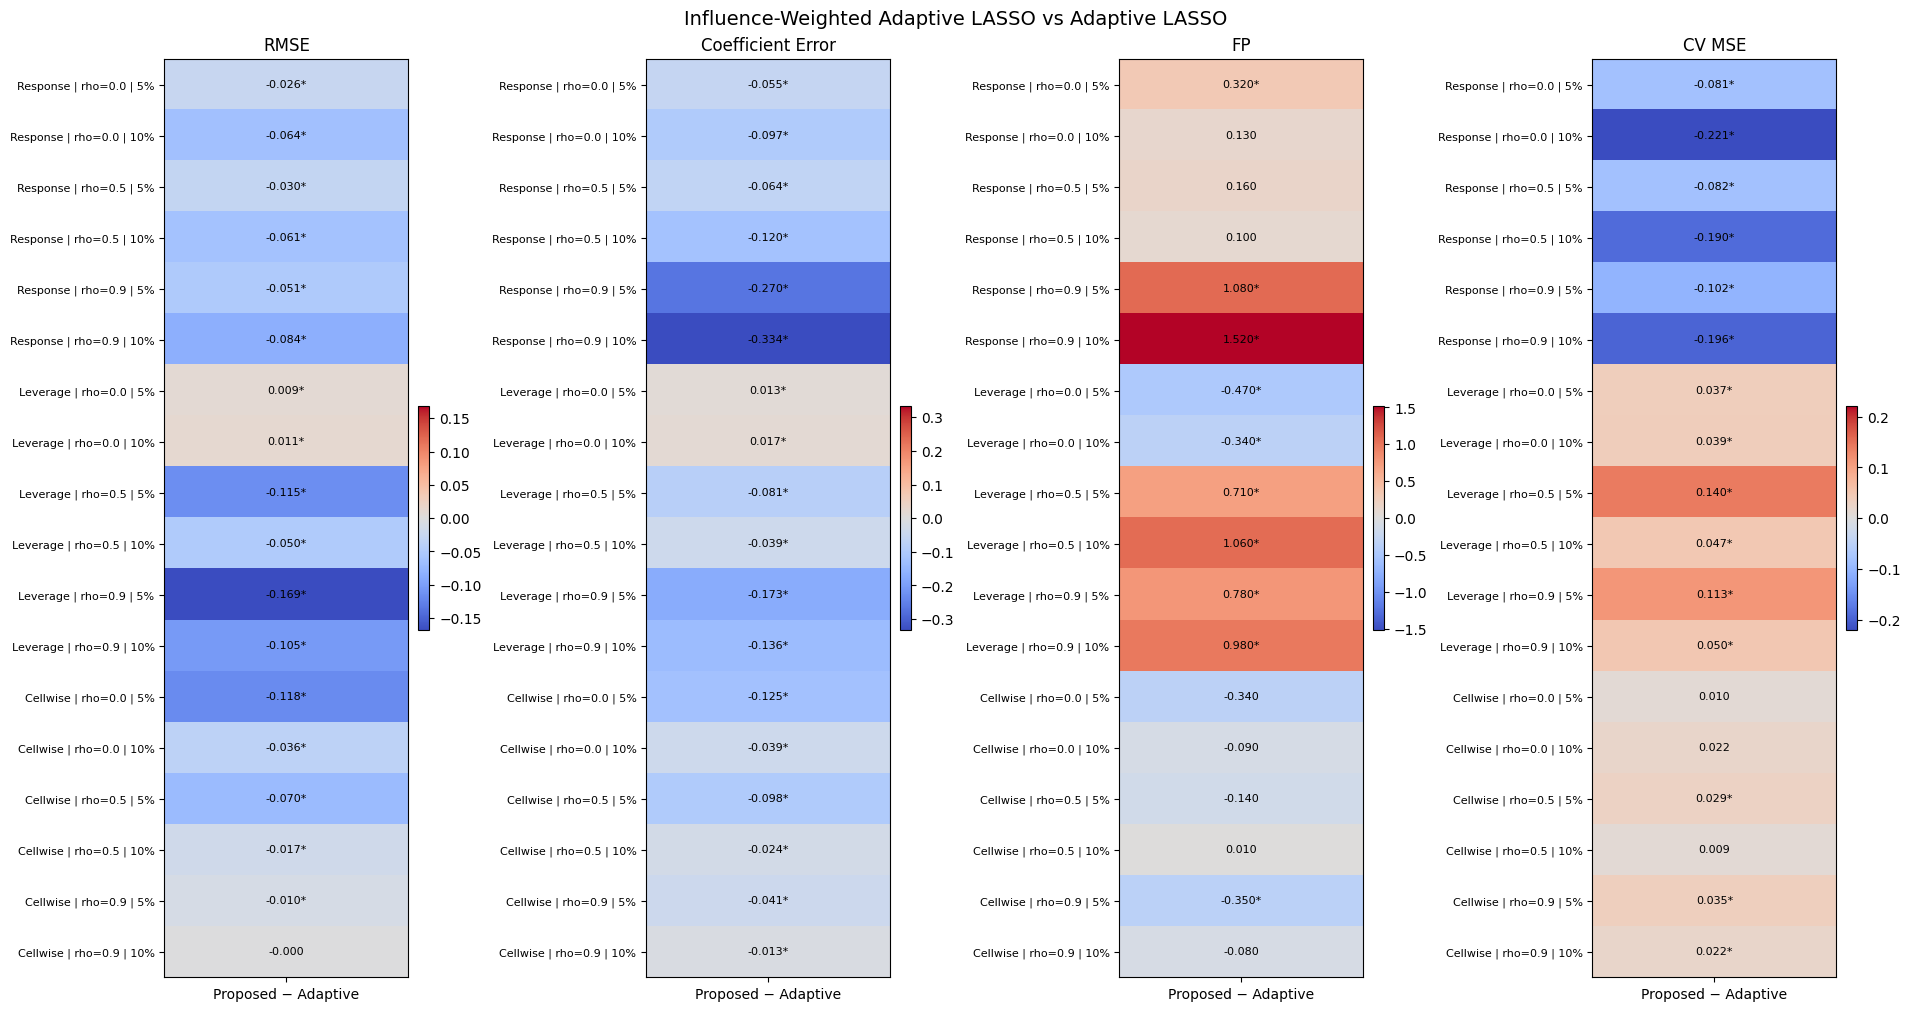

Saved: /content/LASSO_Final_Research_Results/Figure_Contamination_Comparison_Heatmap.png
* indicates Holm-adjusted p < 0.05.
Negative differences favour the proposed method for all four metrics.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = "/content/LASSO_Final_Research_Results"

tests = pd.read_csv(
    f"{RESULTS_DIR}/paired_statistical_tests.csv"
)

metrics = [
    "RMSE",
    "Coefficient_Error",
    "FP",
    "CV_MSE"
]

data = tests[
    (tests["contamination"] > 0) &
    (tests["Metric"].isin(metrics))
].copy()

data["Condition"] = (
    data["contamination_type"].str.capitalize()
    + " | rho=" + data["rho"].astype(str)
    + " | " + (100 * data["contamination"]).astype(int).astype(str)
    + "%"
)

condition_order = (
    data[["condition_id", "Condition",
          "contamination_type", "rho", "contamination"]]
    .drop_duplicates()
    .sort_values(
        ["contamination_type", "rho", "contamination"],
        key=lambda col: col.map({
            "response": 0, "leverage": 1, "cellwise": 2
        }) if col.name == "contamination_type" else col
    )
)

labels = condition_order["Condition"].tolist()

fig, axes = plt.subplots(
    1, 4, figsize=(19, 10), constrained_layout=True
)

for ax, metric in zip(axes, metrics):

    subset = data[data["Metric"] == metric]

    pivot = subset.pivot(
        index="Condition",
        columns="Metric",
        values="Mean_Difference_Proposed_minus_Adaptive"
    ).reindex(labels)

    values = pivot[metric].to_numpy()
    limit = max(np.max(np.abs(values)), 1e-10)

    image = ax.imshow(
        values.reshape(-1, 1),
        aspect="auto",
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit
    )

    for i, condition in enumerate(labels):
        row = subset[subset["Condition"] == condition]
        if len(row):
            value = row.iloc[0][
                "Mean_Difference_Proposed_minus_Adaptive"
            ]
            significant = row.iloc[0]["Holm_Adjusted_P"] < 0.05
            marker = "*" if significant else ""
            ax.text(
                0, i, f"{value:.3f}{marker}",
                ha="center", va="center", fontsize=8
            )

    ax.set_title(metric.replace("_", " "))
    ax.set_xticks([0])
    ax.set_xticklabels(["Proposed − Adaptive"])
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle(
    "Influence-Weighted Adaptive LASSO vs Adaptive LASSO",
    fontsize=14
)

output_path = (
    f"{RESULTS_DIR}/Figure_Contamination_Comparison_Heatmap.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)
print("* indicates Holm-adjusted p < 0.05.")
print("Negative differences favour the proposed method for all four metrics.")


In [ ]:

from google.colab import files

figure_path = (
    "/content/LASSO_Final_Research_Results/"
    "Figure_Contamination_Comparison_Heatmap.png"
)

files.download(figure_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

RESULTS_DIR = "/content/LASSO_Final_Research_Results"

results = pd.read_csv(
    f"{RESULTS_DIR}/full_simulation_results.csv"
)

metrics = [
    "RMSE", "R2", "Coefficient_Error",
    "Precision", "Recall", "FP",
    "Selected", "CV_MSE", "Runtime_seconds"
]

summary = (
    results.groupby([
        "rho", "contamination",
        "contamination_type", "Method"
    ])[metrics]
    .agg(["mean", "std"])
    .round(4)
)

summary.to_csv(
    f"{RESULTS_DIR}/publication_master_summary.csv"
)

print("PUBLICATION MASTER SUMMARY")
print("Rows:", len(summary))
display(summary)

print("\nSaved:",
      f"{RESULTS_DIR}/publication_master_summary.csv")
print("CELL COMPLETED")


PUBLICATION MASTER SUMMARY
Rows: 84


RMSE  \
                                                                          mean   
rho contamination contamination_type Method                                      
0.0 0.00          none               Adaptive LASSO                     1.0223   
                                     Elastic Net                        1.0551   
                                     Influence-Weighted Adaptive LASSO  1.0257   
                                     Ordinary LASSO                     1.0413   
    0.05          cellwise           Adaptive LASSO                     2.9883   
...                                                                        ...   
0.9 0.10          leverage           Ordinary LASSO                     2.4206   
                  response           Adaptive LASSO                     1.4238   
                                     Elastic Net                        1.3940   
                                     Influence-Weighted Adaptive LASSO  1.3395   
                                     Ordinary LASSO                     1.3917   

                                                                                \
                                                                           std   
rho contamination contamination_type Method                                      
0.0 0.00          none               Adaptive LASSO                     0.0678   
                                     Elastic Net                        0.0705   
                                     Influence-Weighted Adaptive LASSO  0.0686   
                                     Ordinary LASSO                     0.0700   
    0.05          cellwise           Adaptive LASSO                     0.3110   
...                                                                        ...   
0.9 0.10          leverage           Ordinary LASSO                     0.1840   
                  response           Adaptive LASSO                     0.1756   
                                     Elastic Net                        0.1600   
                                     Influence-Weighted Adaptive LASSO  0.1602   
                                     Ordinary LASSO                     0.1742   

                                                                            R2  \
                                                                          mean   
rho contamination contamination_type Method                                      
0.0 0.00          none               Adaptive LASSO                     0.9535   
                                     Elastic Net                        0.9505   
                                     Influence-Weighted Adaptive LASSO  0.9532   
                                     Ordinary LASSO                     0.9518   
    0.05          cellwise           Adaptive LASSO                     0.5995   
...                                                                        ...   
0.9 0.10          leverage           Ordinary LASSO                     0.4720   
                  response           Adaptive LASSO                     0.8179   
                                     Elastic Net                        0.8259   
                                     Influence-Weighted Adaptive LASSO  0.8394   
                                     Ordinary LASSO                     0.8262   

                                                                                \
                                                                           std   
rho contamination contamination_type Method                                      
0.0 0.00          none               Adaptive LASSO                     0.0074   
                                     Elastic Net                        0.0077   
                                     Influence-Weighted Adaptive LASSO  0.0074   
                                     Ordinary LASSO                     0.0074   
    0.05          cellwise           Adaptive LASSO  


Saved: /content/LASSO_Final_Research_Results/publication_master_summary.csv
CELL COMPLETED


In [ ]:

import pandas as pd

RESULTS_DIR = "/content/LASSO_Final_Research_Results"

summary = pd.read_csv(
    f"{RESULTS_DIR}/publication_master_summary.csv",
    header=[0, 1],
    index_col=[0, 1, 2, 3]
)

# Retain the two principal methods
methods = [
    "Adaptive LASSO",
    "Influence-Weighted Adaptive LASSO"
]

metrics = [
    "RMSE",
    "R2",
    "Coefficient_Error",
    "Precision",
    "Recall",
    "FP",
    "CV_MSE"
]

rows = []

for index, values in summary.iterrows():
    rho, contamination, contamination_type, method = index

    if method not in methods:
        continue

    row = {
        "rho": rho,
        "contamination": contamination,
        "contamination_type": contamination_type,
        "Method": method
    }

    for metric in metrics:
        mean = values[(metric, "mean")]
        std = values[(metric, "std")]
        row[metric] = f"{mean:.4f} ± {std:.4f}"

    rows.append(row)

compact = pd.DataFrame(rows)

compact = compact.sort_values(
    ["contamination_type", "rho", "contamination", "Method"]
)

compact.to_csv(
    f"{RESULTS_DIR}/compact_publication_comparison.csv",
    index=False
)

print("COMPACT PUBLICATION TABLE")
print("Rows:", len(compact))
display(compact)

print("\nSaved:",
      f"{RESULTS_DIR}/compact_publication_comparison.csv")
print("CELL COMPLETED")


COMPACT PUBLICATION TABLE
Rows: 42


,rho,contamination,contamination_type,Method,RMSE,R2,Coefficient_Error,Precision,Recall,FP,CV_MSE
2,0.0,0.05,cellwise,Adaptive LASSO,2.9883 ± 0.3110,0.5995 ± 0.0749,2.7742 ± 0.2936,0.7720 ± 0.2104,0.9800 ± 0.0876,2.2000 ± 2.9644,14.0586 ± 1.7199
3,0.0,0.05,cellwise,Influence-Weighted Adaptive LASSO,2.8704 ± 0.3063,0.6299 ± 0.0726,2.6496 ± 0.2996,0.8000 ± 0.2072,0.9820 ± 0.0757,1.8600 ± 2.5821,14.0686 ± 1.7320
8,0.0,0.10,cellwise,Adaptive LASSO,3.6793 ± 0.3635,0.3934 ± 0.0697,3.5243 ± 0.2103,0.7319 ± 0.2070,0.9360 ± 0.1267,2.3800 ± 2.3944,17.3512 ± 1.8570
9,0.0,0.10,cellwise,Influence-Weighted Adaptive LASSO,3.6432 ± 0.3704,0.4052 ± 0.0714,3.4858 ± 0.2184,0.7386 ± 0.2082,0.9320 ± 0.1309,2.2900 ± 2.3838,17.3730 ± 1.8842
16,0.5,0.05,cellwise,Adaptive LASSO,2.6556 ± 0.2539,0.5572 ± 0.0733,3.4036 ± 0.2379,0.5396 ± 0.1939,0.9020 ± 0.1348,5.1000 ± 3.3830,10.1851 ± 1.2208
17,0.5,0.05,cellwise,Influence-Weighted Adaptive LASSO,2.5853 ± 0.2602,0.5799 ± 0.0747,3.3056 ± 0.2566,0.5494 ± 0.1973,0.9040 ± 0.1348,4.9600 ± 3.3753,10.2142 ± 1.2465
22,0.5,0.10,cellwise,Adaptive LASSO,3.0430 ± 0.2571,0.4208 ± 0.0683,3.9382 ± 0.1492,0.4253 ± 0.1539,0.7700 ± 0.2038,6.3600 ± 3.6474,11.7039 ± 1.3400
23,0.5,0.10,cellwise,Influence-Weighted Adaptive LASSO,3.0261 ± 0.2604,0.4271 ± 0.0697,3.9141 ± 0.1542,0.4313 ± 0.1629,0.7780 ± 0.2048,6.3700 ± 3.6836,11.7127 ± 1.3443
30,0.9,0.05,cellwise,Adaptive LASSO,1.7224 ± 0.1340,0.7219 ± 0.0472,4.2723 ± 0.1600,0.2581 ± 0.0582,0.7140 ± 0.1564,10.4100 ± 1.8915,4.2946 ± 0.5675
31,0.9,0.05,cellwise,Influence-Weighted Adaptive LASSO,1.7121 ± 0.1354,0.7251 ± 0.0472,4.2316 ± 0.1723,0.2608 ± 0.0556,0.7040 ± 0.1517,10.0600 ± 1.5493,4.3297 ± 0.5836



Saved: /content/LASSO_Final_Research_Results/compact_publication_comparison.csv
CELL COMPLETED


In [ ]:

import inspect

functions_to_check = [
    "calculate_fold_influence_weights",
    "fit_final_simulation"
]

for function_name in functions_to_check:
    print("\n" + "=" * 75)
    print("FUNCTION:", function_name)
    print("=" * 75)

    function_object = globals().get(function_name)

    if function_object is None:
        print("Function not found in current runtime.")
    else:
        try:
            print(inspect.getsource(function_object))
        except Exception as error:
            print("Could not retrieve source:", error)



FUNCTION: calculate_fold_influence_weights
def calculate_fold_influence_weights(X, y, alpha):
    """
    Calculate observation-level influence weights using
    only the observations supplied to this function.
    """

    n, p = X.shape

    reference = Lasso(
        alpha=alpha,
        max_iter=50000
    )
    reference.fit(X, y)

    reference_coef = reference.coef_
    reference_selected = np.abs(reference_coef) > 1e-6

    model_change = np.zeros(n)
    coefficient_change = np.zeros(n)

    for i in range(n):

        keep = np.arange(n) != i

        model = Lasso(
            alpha=alpha,
            max_iter=50000
        )

        model.fit(X[keep], y[keep])

        model_change[i] = np.sum(
            (np.abs(model.coef_) > 1e-6)
            != reference_selected
        )

        coefficient_change[i] = np.sum(
            np.abs(model.coef_ - reference_coef)
        )

    # Robust residual score
    residuals = y - reference.predict(X)

    residual_median = np.med

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

scenarios = [
    ("Clean", 0.0, "none"),
    ("Response", 0.05, "response"),
    ("Leverage", 0.05, "leverage"),
    ("Cellwise", 0.05, "cellwise")
]

weight_diagnostics = []

for label, contamination, contamination_type in scenarios:

    X, y, _ = generate_synthetic_data(
        n=N,
        p=P,
        rho=0.5,
        contamination=contamination,
        contamination_type=contamination_type,
        seed=2026
    )

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    weights = calculate_fold_influence_weights(
        X_scaled, y, alpha=0.1
    )

    weight_diagnostics.append({
        "Scenario": label,
        "Minimum": np.min(weights),
        "Q25": np.percentile(weights, 25),
        "Median": np.median(weights),
        "Q75": np.percentile(weights, 75),
        "Maximum": np.max(weights),
        "Mean": np.mean(weights),
        "Standard_Deviation": np.std(weights),
        "Effective_Sample_Size": (
            np.sum(weights) ** 2 / np.sum(weights ** 2)
        )
    })

weight_table = pd.DataFrame(weight_diagnostics).round(4)

display(weight_table)

weight_table.to_csv(
    "/content/LASSO_Final_Research_Results/influence_weight_diagnostics.csv",
    index=False
)

print("Saved influence_weight_diagnostics.csv")
print("CELL COMPLETED")

,Scenario,Minimum,Q25,Median,Q75,Maximum,Mean,Standard_Deviation,Effective_Sample_Size
0,Clean,0.5858,0.7863,0.9767,1.1967,1.5953,1.0,0.2579,187.5273
1,Response,0.4961,0.7443,0.9200,1.2219,1.6794,1.0,0.2996,183.5294
2,Leverage,0.4989,0.7804,0.9846,1.1795,1.5885,1.0,0.2661,186.7716
3,Cellwise,0.5016,0.7591,0.9345,1.2466,1.6978,1.0,0.3053,182.9432


Saved influence_weight_diagnostics.csv
CELL COMPLETED


In [ ]:
print("Checking research results...")

import os

results_folder = "/content/LASSO_Final_Research_Results"

print("Results folder exists:", os.path.exists(results_folder))

if os.path.exists(results_folder):
    print("\nAvailable result files:")
    for file in sorted(os.listdir(results_folder)):
        print(file)

Checking research results...
Results folder exists: False
